# 01. Dataset Audit & Leakage-Safe Splitting
**AI-Based Resume–Job Matching & Skill Gap Analysis**

### Purpose of this Notebook:
1. **Initial Dataset Audit**: Conduct an exploratory audit of the `resume-job-description-fit` dataset (`data/raw/train.csv` and `data/raw/test.csv`), validating resume repetitions, job repetitions, pair duplicates, and cross-split overlap.
2. **Evaluation Strategy Confirmation**: Document why the official test set is preserved as an *"unseen-job-description benchmark"* (99.79% resumes in test overlap with train, but 0% job descriptions overlap).
3. **Leakage-Safe Candidate-Level Split**: Construct an *"unseen-candidate evaluation"* split using `StratifiedGroupKFold` (60% Train / 20% Validation / 20% Test) grouped by candidate resume to eliminate data leakage.
4. **Verification**: Mathematically and programmatically verify that all split intersections are strictly disjoint (0 candidate overlap) and inspect stratified label distributions.
5. **Persist Leakage-Safe Splits**: Export the partitioned datasets to `data/processed/` with column and mutual exclusivity verification.

> **Constraint Reminders**:
> - Original raw CSVs (`train.csv`, `test.csv`) are strictly read-only and preserved unmodified.
> - No machine learning models are trained in this notebook.
> - No unnecessary external dependencies are introduced.

## 1. Environment Setup & Data Ingestion

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedGroupKFold

# Load the raw training and official test datasets
train_df = pd.read_csv('../data/raw/train.csv')
official_test_df = pd.read_csv('../data/raw/test.csv')

print(f"Raw Training Shape:       {train_df.shape[0]:,} rows | {train_df.shape[1]} columns")
print(f"Official Test Shape:      {official_test_df.shape[0]:,} rows | {official_test_df.shape[1]} columns")
print(f"Columns:                  {train_df.columns.tolist()}")

## 2. Dataset Audit & Structural Findings

In this section, we verify the structural properties and repetitions present in the raw data:
- Repetitions of resumes across different job postings
- Repetitions of job descriptions across multiple candidates
- Duplicate `(resume, job_description)` pairs
- Resumes associated with multiple outcome labels
- Overlap between the official training set and official test set

In [ ]:
# 1. Unique counts in training
train_rows = len(train_df)
unique_train_resumes = train_df['resume_text'].nunique()
unique_train_jds = train_df['job_description_text'].nunique()

# 2. Resume repetition statistics
resume_counts = train_df['resume_text'].value_counts()
resumes_multi = (resume_counts > 1).sum()
max_resume_reps = resume_counts.max()

# 3. Job description repetition statistics
jd_counts = train_df['job_description_text'].value_counts()
jds_multi = (jd_counts > 1).sum()
max_jd_reps = jd_counts.max()

# 4. Duplicate resume-job pairs
duplicate_pairs = train_df.duplicated(subset=['resume_text', 'job_description_text']).sum()

# 5. Resumes associated with multiple labels across different jobs
resumes_with_multi_labels = (train_df.groupby('resume_text')['label'].nunique() > 1).sum()

print("=" * 60)
print("TRAINING SET STRUCTURAL AUDIT")
print("=" * 60)
print(f"Training rows:                      {train_rows:,}")
print(f"Unique resumes:                     {unique_train_resumes:,}")
print(f"Unique job descriptions:            {unique_train_jds:,}")
print(f"Resumes appearing more than once:   {resumes_multi:,} ({(resumes_multi/unique_train_resumes)*100:.1f}%)")
print(f"Maximum resume repetitions:         {max_resume_reps:,}")
print(f"JDs appearing more than once:       {jds_multi:,} ({(jds_multi/unique_train_jds)*100:.1f}%)")
print(f"Maximum JD repetitions:             {max_jd_reps:,}")
print(f"Duplicate (resume, JD) pairs:       {duplicate_pairs:,}")
print(f"Resumes with multiple labels:       {resumes_with_multi_labels:,}")

### 2.1 Official Test Set Overlap Analysis

Next, we analyze the relationship between the official training set and the official test set.

In [ ]:
test_rows = len(official_test_df)
unique_test_resumes = official_test_df['resume_text'].nunique()
unique_test_jds = official_test_df['job_description_text'].nunique()

# Check resume overlap: unique test resumes that also appear in training
train_resume_set = set(train_df['resume_text'])
test_resume_set = set(official_test_df['resume_text'])
resumes_in_both = test_resume_set.intersection(train_resume_set)

# Check JD overlap: unique test JDs that appear in training
train_jd_set = set(train_df['job_description_text'])
test_jd_set = set(official_test_df['job_description_text'])
jds_in_both = test_jd_set.intersection(train_jd_set)

# Check exact (resume, JD) pair overlap
train_pairs = set(zip(train_df['resume_text'], train_df['job_description_text']))
test_pairs = set(zip(official_test_df['resume_text'], official_test_df['job_description_text']))
pair_overlap = train_pairs.intersection(test_pairs)

print("=" * 60)
print("OFFICIAL TEST SET OVERLAP AUDIT")
print("=" * 60)
print(f"Official test rows:                 {test_rows:,}")
print(f"Unique test resumes:                {unique_test_resumes:,}")
print(f"Unique test job descriptions:       {unique_test_jds:,}")
print(f"Test resumes appearing in train:    {len(resumes_in_both):,} / {unique_test_resumes} ({(len(resumes_in_both)/unique_test_resumes)*100:.2f}%)")
print(f"Test JDs appearing in train:        {len(jds_in_both):,} / {unique_test_jds} ({(len(jds_in_both)/unique_test_jds)*100:.2f}%)")
print(f"Exact (resume, JD) pair overlap:    {len(pair_overlap):,}")

In [ ]:
# Compare label distributions between official train and test
label_dist = pd.DataFrame({
    'Train Count': train_df['label'].value_counts(),
    'Train %': (train_df['label'].value_counts(normalize=True) * 100).round(2),
    'Test Count': official_test_df['label'].value_counts(),
    'Test %': (official_test_df['label'].value_counts(normalize=True) * 100).round(2)
})

print("=" * 60)
print("LABEL DISTRIBUTION: OFFICIAL TRAIN vs. OFFICIAL TEST")
print("=" * 60)
display(label_dist)

## 3. Evaluation Paradigm & Strategic Decision

Based on the audit findings:
1. **Official Test Set as 'Unseen-Job-Description Benchmark'**:
   - In the official test set, **0 out of 71 job descriptions** exist in the training set. However, **476 out of 477 resumes (99.79%)** were already present in the training data.
   - Therefore, the official test set tests how a model generalizes to *new job descriptions* when candidates are already familiar.
   
2. **Need for 'Unseen-Candidate Benchmark' (Leakage-Safe Split)**:
   - In real-world recruitment, the primary challenge is evaluating *new candidates* whose resumes the model has never encountered.
   - If candidate resumes overlap between train and test, models can memorize resume-specific text patterns, tokens, or candidate idiosyncrasies, creating severe **data leakage** and overly optimistic test scores.
   - **Solution**: We perform a grouped split on `train.csv` using `StratifiedGroupKFold` with `resume_text` as the grouping key. This guarantees that any given candidate is strictly isolated to either Train, Validation, or Test.

## 4. Leakage-Safe Candidate-Level Split Implementation

We apply `StratifiedGroupKFold` from `sklearn.model_selection` with:
- **Grouping variable**: `resume_text` (all rows belonging to a candidate stay together)
- **Stratification variable**: `label` (balances `No Fit`, `Potential Fit`, and `Good Fit` classes)
- **`n_splits=5`** with **`random_state=42`** and **`shuffle=True`**:
  - Each fold contains approximately 20% of the candidate groups.
  - **Candidate Train**: Folds `[2, 3, 4]` (~60% of data)
  - **Candidate Validation**: Fold `1` (~20% of data)
  - **Candidate Test**: Fold `0` (~20% of data)

In [ ]:
# 1. Initialize StratifiedGroupKFold
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

# 2. Assign each row to a fold index (0 to 4)
fold_assignments = np.zeros(len(train_df), dtype=int)
for fold_idx, (train_indices, fold_indices) in enumerate(
    sgkf.split(train_df, train_df['label'], groups=train_df['resume_text'])
):
    fold_assignments[fold_indices] = fold_idx

# Store fold assignment in a working copy (without modifying original data)
df_split = train_df.copy()
df_split['fold'] = fold_assignments

# 3. Create approximately 60% Train, 20% Val, 20% Test splits
candidate_train = df_split[df_split['fold'].isin([2, 3, 4])].drop(columns=['fold']).reset_index(drop=True)
candidate_val   = df_split[df_split['fold'] == 1].drop(columns=['fold']).reset_index(drop=True)
candidate_test  = df_split[df_split['fold'] == 0].drop(columns=['fold']).reset_index(drop=True)

print("Split assignment completed successfully.")

## 5. Explicit Leakage Verification

We now explicitly verify that the candidate resumes in the three splits are completely disjoint:
- $\text{train} \cap \text{validation} = \emptyset$
- $\text{train} \cap \text{test} = \emptyset$
- $\text{validation} \cap \text{test} = \emptyset$

In [ ]:
# Extract unique resume sets
resumes_train = set(candidate_train['resume_text'])
resumes_val   = set(candidate_val['resume_text'])
resumes_test  = set(candidate_test['resume_text'])

# Compute set intersections
inter_tr_val   = resumes_train.intersection(resumes_val)
inter_tr_test  = resumes_train.intersection(resumes_test)
inter_val_test = resumes_val.intersection(resumes_test)

print("=" * 60)
print("LEAKAGE VERIFICATION (INTERSECTION AUDIT)")
print("=" * 60)
print(f"train ∩ validation resumes : {len(inter_tr_val)}")
print(f"train ∩ test resumes       : {len(inter_tr_test)}")
print(f"validation ∩ test resumes  : {len(inter_val_test)}")

# Programmatic assertion checks
assert len(inter_tr_val) == 0, f"Leakage detected: {len(inter_tr_val)} resumes shared between train and val"
assert len(inter_tr_test) == 0, f"Leakage detected: {len(inter_tr_test)} resumes shared between train and test"
assert len(inter_val_test) == 0, f"Leakage detected: {len(inter_val_test)} resumes shared between val and test"

# Verify all resumes from training are accounted for
total_split_resumes = len(resumes_train) + len(resumes_val) + len(resumes_test)
assert total_split_resumes == unique_train_resumes, (
    f"Mismatch: sum of split resumes ({total_split_resumes}) != total unique resumes ({unique_train_resumes})"
)

print("\nSUCCESS: Zero candidate leakage verified across all splits!")
print(f"Total unique resumes accounted for: {total_split_resumes:,} / {unique_train_resumes:,}")

## 6. Split Overview & Label Distribution Analysis

Here we examine the row counts, unique resume counts, and label stratification for all three splits.

In [ ]:
splits_dict = {
    'Candidate Train (Folds 2, 3, 4)': candidate_train,
    'Candidate Val (Fold 1)': candidate_val,
    'Candidate Test (Fold 0)': candidate_test
}

summary_rows = []
for split_name, s_df in splits_dict.items():
    row_count = len(s_df)
    row_pct = (row_count / train_rows) * 100
    res_count = s_df['resume_text'].nunique()
    res_pct = (res_count / unique_train_resumes) * 100
    
    # Label counts & percentages
    lbl_counts = s_df['label'].value_counts()
    lbl_pcts = s_df['label'].value_counts(normalize=True) * 100
    
    summary_rows.append({
        'Split': split_name,
        'Rows': f"{row_count:,}",
        'Row %': f"{row_pct:.2f}%",
        'Unique Resumes': f"{res_count:,}",
        'Resume %': f"{res_pct:.2f}%",
        'No Fit (count)': lbl_counts.get('No Fit', 0),
        'No Fit (%)': f"{lbl_pcts.get('No Fit', 0.0):.2f}%",
        'Potential Fit (count)': lbl_counts.get('Potential Fit', 0),
        'Potential Fit (%)': f"{lbl_pcts.get('Potential Fit', 0.0):.2f}%",
        'Good Fit (count)': lbl_counts.get('Good Fit', 0),
        'Good Fit (%)': f"{lbl_pcts.get('Good Fit', 0.0):.2f}%"
    })

summary_df = pd.DataFrame(summary_rows)
display(summary_df)

In [ ]:
print("=" * 65)
print("DETAILED SPLIT REPORT")
print("=" * 65)

for split_name, s_df in splits_dict.items():
    print(f"\n[{split_name.upper()}]")
    print(f"  Rows:            {len(s_df):,} ({len(s_df)/train_rows*100:.2f}% of total rows)")
    print(f"  Unique Resumes:  {s_df['resume_text'].nunique():,} ({s_df['resume_text'].nunique()/unique_train_resumes*100:.2f}% of unique resumes)")
    print("  Label Counts & Percentages:")
    counts = s_df['label'].value_counts()
    pcts = s_df['label'].value_counts(normalize=True) * 100
    for label in ['No Fit', 'Potential Fit', 'Good Fit']:
        print(f"    - {label:<14}: {counts.get(label, 0):>5,} ({pcts.get(label, 0.0):>5.2f}%)")

print("\n" + "=" * 65)
print("VERIFICATION COMPLETED")
print("=" * 65)

## Persist Leakage-Safe Candidate Splits

We now save the three candidate-level datasets locally to `data/processed/`:
1. `candidate_train.csv` (from `candidate_train`)
2. `candidate_validation.csv` (from `candidate_val`)
3. `candidate_test.csv` (from `candidate_test`)

**Integrity Requirements Enforced**:
- Raw datasets (`data/raw/train.csv` and `data/raw/test.csv`) remain completely untouched.
- All original columns (`resume_text`, `job_description_text`, `label`) are preserved.
- Files are saved with `index=False`.
- After persisting, all three files are reloaded from disk and verified for shapes, mutual exclusivity, and complete candidate accounting (642/642 resumes).

In [ ]:
import os

output_dir = '../data/processed'
os.makedirs(output_dir, exist_ok=True)

train_path = os.path.join(output_dir, 'candidate_train.csv')
val_path   = os.path.join(output_dir, 'candidate_validation.csv')
test_path  = os.path.join(output_dir, 'candidate_test.csv')

# Verify required columns are present
expected_cols = ['resume_text', 'job_description_text', 'label']
assert list(candidate_train.columns) == expected_cols, f"Unexpected columns in candidate_train: {candidate_train.columns}"
assert list(candidate_val.columns) == expected_cols, f"Unexpected columns in candidate_val: {candidate_val.columns}"
assert list(candidate_test.columns) == expected_cols, f"Unexpected columns in candidate_test: {candidate_test.columns}"

# Export to CSV with index=False
candidate_train.to_csv(train_path, index=False)
candidate_val.to_csv(val_path, index=False)
candidate_test.to_csv(test_path, index=False)

print(f"Saved: {train_path} ({len(candidate_train):,} rows)")
print(f"Saved: {val_path} ({len(candidate_val):,} rows)")
print(f"Saved: {test_path} ({len(candidate_test):,} rows)")

### Verification of Persisted Datasets

To ensure file integrity, we reload the CSV files from `data/processed/`, confirm shapes and column names, verify that candidate resume sets remain mutually exclusive, and confirm that all 642 original resumes are accounted for.

In [ ]:
# 1. Reload saved CSV files from data/processed/
reloaded_train = pd.read_csv(train_path)
reloaded_val   = pd.read_csv(val_path)
reloaded_test  = pd.read_csv(test_path)

# 2. Print shapes and columns
print("=" * 60)
print("RELOADED CSV SHAPE & COLUMN VERIFICATION")
print("=" * 60)
print(f"candidate_train.csv:      {reloaded_train.shape[0]:,} rows x {reloaded_train.shape[1]} cols")
print(f"candidate_validation.csv: {reloaded_val.shape[0]:,} rows x {reloaded_val.shape[1]} cols")
print(f"candidate_test.csv:       {reloaded_test.shape[0]:,} rows x {reloaded_test.shape[1]} cols")

assert reloaded_train.shape == candidate_train.shape, "Train shape mismatch after reload"
assert reloaded_val.shape == candidate_val.shape, "Validation shape mismatch after reload"
assert reloaded_test.shape == candidate_test.shape, "Test shape mismatch after reload"

for name, df_reloaded in [('train', reloaded_train), ('val', reloaded_val), ('test', reloaded_test)]:
    assert df_reloaded.columns.tolist() == expected_cols, f"Columns mismatch in {name}: {df_reloaded.columns.tolist()}"

# 3. Extract reloaded resume sets
reloaded_resumes_train = set(reloaded_train['resume_text'])
reloaded_resumes_val   = set(reloaded_val['resume_text'])
reloaded_resumes_test  = set(reloaded_test['resume_text'])

# 4. Verify mutual exclusivity
reloaded_inter_tr_val   = reloaded_resumes_train.intersection(reloaded_resumes_val)
reloaded_inter_tr_test  = reloaded_resumes_train.intersection(reloaded_resumes_test)
reloaded_inter_val_test = reloaded_resumes_val.intersection(reloaded_resumes_test)

print("\n" + "=" * 60)
print("MUTUAL EXCLUSIVITY VERIFICATION (RELOADED SETS)")
print("=" * 60)
print(f"reloaded train ∩ validation resumes : {len(reloaded_inter_tr_val)}")
print(f"reloaded train ∩ test resumes       : {len(reloaded_inter_tr_test)}")
print(f"reloaded validation ∩ test resumes  : {len(reloaded_inter_val_test)}")

assert len(reloaded_inter_tr_val) == 0, f"Overlap detected between train and val: {len(reloaded_inter_tr_val)}"
assert len(reloaded_inter_tr_test) == 0, f"Overlap detected between train and test: {len(reloaded_inter_tr_test)}"
assert len(reloaded_inter_val_test) == 0, f"Overlap detected between val and test: {len(reloaded_inter_val_test)}"
print("Mutual exclusivity verified: Zero candidate leakage.")

# 5. Verify all 642 original resumes are accounted for
total_reloaded_resumes = len(reloaded_resumes_train) + len(reloaded_resumes_val) + len(reloaded_resumes_test)
print("\n" + "=" * 60)
print("ORIGINAL RESUME ACCOUNTING")
print("=" * 60)
print(f"Reloaded Train Resumes:      {len(reloaded_resumes_train):,}")
print(f"Reloaded Validation Resumes: {len(reloaded_resumes_val):,}")
print(f"Reloaded Test Resumes:       {len(reloaded_resumes_test):,}")
print(f"Total Resumes Accounted For: {total_reloaded_resumes:,} / {unique_train_resumes:,}")

assert total_reloaded_resumes == unique_train_resumes == 642, (
    f"Mismatch: expected 642 resumes, found {total_reloaded_resumes}"
)
print("\nSUCCESS: All 642 original training resumes are fully accounted for with zero leakage!")

## 8. Summary & Next Steps

### Completed Milestones:
1. **Preserved Raw Data**: `data/raw/train.csv` and `data/raw/test.csv` remained completely unaltered.
2. **Leakage-Safe Partitioning**: Created disjoint splits using candidate-level grouping via `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)`.
3. **Persisted Processed CSVs**:
   - `data/processed/candidate_train.csv` (3,758 rows, 389 unique resumes)
   - `data/processed/candidate_validation.csv` (1,282 rows, 128 unique resumes)
   - `data/processed/candidate_test.csv` (1,201 rows, 125 unique resumes)
4. **Reload Verification**: Reloaded all files from disk, verified exact shape matches, confirmed preserved column order (`resume_text`, `job_description_text`, `label`), proved mutual exclusivity ($0$ overlap), and confirmed that all 642 original candidates are accounted for.

*Next Step: The dataset foundation is now locked. In the next stage, NLP preprocessing and the classical TF-IDF baseline model will be built.*

## Baseline 1 — TF-IDF + Cosine Similarity

In this section, we establish our first classical machine learning baseline: **TF-IDF (Term Frequency–Inverse Document Frequency) with Cosine Similarity**.

---

### Core Concepts & Architectural Principles

#### 1. What TF-IDF Does
- **Term Frequency ($TF$)**: Quantifies how frequently a term appears in an individual document (resume or job description).
- **Inverse Document Frequency ($IDF$)**: Downweights ubiquitous words that occur across most documents (e.g., *"work"*, *"experience"*, *"team"*) and upweights rare, highly discriminative technical terminology (e.g., *"kubernetes"*, *"pytorch"*, *"actuarial"*):
  $$	ext{IDF}(t, D) = \log\left(rac{1 + |D|}{1 + 	ext{DF}(t)}ight) + 1$$
- **TF-IDF Weighting**: The product $	ext{TF}(t, d) 	imes 	ext{IDF}(t, D)$ yields an informative sparse vector representation of each document where distinctive vocabulary receives highest weight.

#### 2. Why Cosine Similarity is Used
- Resumes and job descriptions exhibit substantial length variance (e.g., a detailed multi-page resume vs. a concise 3-paragraph posting).
- **Cosine similarity** computes the cosine of the angle between two $L_2$-normalized vectors:
  $$	ext{Cosine Similarity}(\mathbf{u}, \mathbf{v}) = rac{\mathbf{u} \cdot \mathbf{v}}{\|\mathbf{u}\|_2 \|\mathbf{v}\|_2}$$
- Because TF-IDF vectors are unit-normalized ($\|\mathbf{u}\|_2 = 1$), the cosine similarity reduces directly to the inner product $\mathbf{u} \cdot \mathbf{v} \in [0, 1]$.
- This provides **length-invariant measurement**: a candidate is evaluated based on the proportion of overlapping lexical terminology rather than the raw word count of their document.

#### 3. Why the Vectorizer is Fitted ONLY on Training Data
- **Strict Leakage Prevention**: In production, incoming resumes and job descriptions are unknown.
- The IDF values represent global corpus statistics. If validation or test texts were included during `fit` or `fit_transform`, the vocabulary and term rarity weights of the evaluation sets would leak into the feature space.
- Therefore, the `TfidfVectorizer` is fitted exclusively on `candidate_train.csv`. Validation and test splits are transformed using the fixed, pre-fitted training vocabulary and IDF weights. Terms appearing exclusively in test or validation are naturally treated as out-of-vocabulary (OOV).

#### 4. Why Classification Thresholds Are NOT Selected Arbitrarily
- Arbitrary heuristics (e.g., $0.7 = 	ext{Good Fit}$, $0.5 = 	ext{Potential Fit}$, $0.3 = 	ext{No Fit}$) assume uniform or centered score distributions.
- In reality, cross-genre text matching (resumes describing personal achievements vs. job descriptions detailing formal candidate specifications) results in sparse lexical overlap, causing cosine similarity scores to concentrate in much lower ranges (typically $0.02 - 0.25$).
- Imposing arbitrary thresholds before inspecting the empirical score distribution would misclassify nearly all pairs as "No Fit".
- Proper decision thresholds or ranking cutoffs must be determined empirically based on validation set calibration.

### 1. Load Persisted Candidate-Level Datasets

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer

# Paths to persisted datasets
processed_dir = '../data/processed'
train_path = os.path.join(processed_dir, 'candidate_train.csv')
val_path   = os.path.join(processed_dir, 'candidate_validation.csv')
test_path  = os.path.join(processed_dir, 'candidate_test.csv')

# Load datasets
train_df = pd.read_csv(train_path)
val_df   = pd.read_csv(val_path)
test_df  = pd.read_csv(test_path)

print(f"Candidate Train Shape:      {train_df.shape[0]:,} rows x {train_df.shape[1]} cols")
print(f"Candidate Validation Shape: {val_df.shape[0]:,} rows x {val_df.shape[1]} cols")
print(f"Candidate Test Shape:       {test_df.shape[0]:,} rows x {test_df.shape[1]} cols")
print(f"Columns: {train_df.columns.tolist()}")

### 2. Fit TF-IDF Vectorizer Strictly on Training Data

We fit the vectorizer on the combined training texts (`resume_text` and `job_description_text`) from `candidate_train.csv` so both documents share an identical feature space. Validation and test documents are transformed using the fitted vectorizer.

In [ ]:
# Clean, standard preprocessing for TF-IDF baseline:
# - Lowercasing enabled by default
# - English stop words removed
# - Preserves alphanumeric and technical terms
tfidf_vectorizer = TfidfVectorizer(
    stop_words='english',
    lowercase=True,
    norm='l2'
)

# IMPORTANT: Fit ONLY on training corpus (resumes + job descriptions)
train_corpus = pd.concat([train_df['resume_text'], train_df['job_description_text']], ignore_index=True)
tfidf_vectorizer.fit(train_corpus)

vocab_size = len(tfidf_vectorizer.vocabulary_)
print(f"TF-IDF Vocabulary Size: {vocab_size:,} unique features")
print(f"Sample features: {list(tfidf_vectorizer.vocabulary_.keys())[:15]}")

# Transform training pairs
train_resume_tfidf = tfidf_vectorizer.transform(train_df['resume_text'])
train_jd_tfidf     = tfidf_vectorizer.transform(train_df['job_description_text'])

# Transform validation pairs (using already-fitted vectorizer)
val_resume_tfidf   = tfidf_vectorizer.transform(val_df['resume_text'])
val_jd_tfidf       = tfidf_vectorizer.transform(val_df['job_description_text'])

# Transform test pairs (using already-fitted vectorizer)
test_resume_tfidf  = tfidf_vectorizer.transform(test_df['resume_text'])
test_jd_tfidf      = tfidf_vectorizer.transform(test_df['job_description_text'])

print(f"\nTransformed Matrix Shapes:")
print(f"  Train Resumes:      {train_resume_tfidf.shape}")
print(f"  Train JDs:          {train_jd_tfidf.shape}")
print(f"  Validation Resumes: {val_resume_tfidf.shape}")
print(f"  Validation JDs:     {val_jd_tfidf.shape}")
print(f"  Test Resumes:       {test_resume_tfidf.shape}")
print(f"  Test JDs:           {test_jd_tfidf.shape}")

### 3. Compute Pairwise Cosine Similarity

Because both matrices are $L_2$-normalized, the cosine similarity between the $i$-th resume and $i$-th job description corresponds to the row-wise dot product:
$$	ext{sim}_i = \sum_{j} \mathbf{R}_{ij} \mathbf{J}_{ij}$$

In [ ]:
# Compute row-wise cosine similarity for corresponding (resume, JD) pairs
train_similarities = np.asarray(train_resume_tfidf.multiply(train_jd_tfidf).sum(axis=1)).ravel()
val_similarities   = np.asarray(val_resume_tfidf.multiply(val_jd_tfidf).sum(axis=1)).ravel()
test_similarities  = np.asarray(test_resume_tfidf.multiply(test_jd_tfidf).sum(axis=1)).ravel()

# Store similarity scores in working copies (without overwriting persisted CSVs)
train_results = train_df.copy()
val_results   = val_df.copy()
test_results  = test_df.copy()

train_results['tfidf_similarity'] = train_similarities
val_results['tfidf_similarity']   = val_similarities
test_results['tfidf_similarity']  = test_similarities

print("Cosine similarity computation completed.")
print(f"Train similarities count: {len(train_similarities):,}")
print(f"Val similarities count:   {len(val_similarities):,}")
print(f"Test similarities count:  {len(test_similarities):,}")

### 4. Similarity Score Descriptive Statistics

We now inspect overall statistics across splits (count, mean, median, standard deviation, minimum, maximum).

In [ ]:
def compute_descriptive_stats(series, name):
    return {
        'Split': name,
        'Count': f"{int(series.count()):,}",
        'Mean': f"{series.mean():.4f}",
        'Std': f"{series.std():.4f}",
        'Min': f"{series.min():.4f}",
        '25%': f"{series.quantile(0.25):.4f}",
        'Median': f"{series.median():.4f}",
        '75%': f"{series.quantile(0.75):.4f}",
        'Max': f"{series.max():.4f}"
    }

overall_stats_df = pd.DataFrame([
    compute_descriptive_stats(train_results['tfidf_similarity'], 'Candidate Train'),
    compute_descriptive_stats(val_results['tfidf_similarity'], 'Candidate Validation'),
    compute_descriptive_stats(test_results['tfidf_similarity'], 'Candidate Test')
])

print("=" * 70)
print("OVERALL TF-IDF COSINE SIMILARITY STATISTICS")
print("=" * 70)
display(overall_stats_df)

### 5. Similarity Score Statistics Grouped by Label

Next, we analyze how the TF-IDF cosine similarity scores behave across the three ground-truth fit categories: **No Fit**, **Potential Fit**, and **Good Fit**.

In [ ]:
def get_label_stats_table(df, split_name):
    grouped = df.groupby('label')['tfidf_similarity'].agg(
        Count='count',
        Mean='mean',
        Std='std',
        Min='min',
        Median='median',
        Max='max'
    ).reindex(['No Fit', 'Potential Fit', 'Good Fit'])
    
    # Format table for clean display
    formatted = grouped.copy()
    formatted['Count'] = formatted['Count'].apply(lambda x: f"{x:,}")
    for col in ['Mean', 'Std', 'Min', 'Median', 'Max']:
        formatted[col] = formatted[col].apply(lambda x: f"{x:.4f}")
    
    formatted.columns = pd.MultiIndex.from_product([[split_name], formatted.columns])
    return formatted

train_label_stats = get_label_stats_table(train_results, 'Train')
val_label_stats   = get_label_stats_table(val_results, 'Validation')
test_label_stats  = get_label_stats_table(test_results, 'Test')

combined_label_stats = pd.concat([train_label_stats, val_label_stats, test_label_stats], axis=1)

print("=" * 80)
print("TF-IDF COSINE SIMILARITY STATISTICS GROUPED BY LABEL")
print("=" * 80)
display(combined_label_stats)

In [ ]:
# Formatted console report for all three splits
for split_name, df_res in [('CANDIDATE TRAIN', train_results), 
                           ('CANDIDATE VALIDATION', val_results), 
                           ('CANDIDATE TEST', test_results)]:
    print(f"\n{'='*30} {split_name} {'='*30}")
    for label in ['No Fit', 'Potential Fit', 'Good Fit']:
        sub = df_res[df_res['label'] == label]['tfidf_similarity']
        print(f"  {label:<14} | Count: {len(sub):>4,} | Mean: {sub.mean():.4f} | Median: {sub.median():.4f} | Std: {sub.std():.4f} | Range: [{sub.min():.4f}, {sub.max():.4f}]")

### 6. Visualizing Similarity Score Distributions

We visualize the distribution of TF-IDF similarity scores across the three fit categories using:
1. **Kernel Density Estimation (KDE) / Histograms**: To observe the score spread and modal peaks.
2. **Boxplots**: To compare medians, interquartile ranges (IQR), and outliers across classes.

In [ ]:
# Set plot style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

palette = {'No Fit': '#e74c3c', 'Potential Fit': '#f39c12', 'Good Fit': '#2ecc71'}
label_order = ['No Fit', 'Potential Fit', 'Good Fit']

# 1. KDE Distribution Plot on Validation Set
ax1 = axes[0]
for label in label_order:
    subset = val_results[val_results['label'] == label]['tfidf_similarity']
    sns.kdeplot(
        subset,
        ax=ax1,
        label=f"{label} (Median: {subset.median():.3f})",
        color=palette[label],
        fill=True,
        alpha=0.25,
        linewidth=2
    )

ax1.set_title("Validation Set: TF-IDF Similarity Distribution (KDE)", fontsize=13, fontweight='bold')
ax1.set_xlabel("TF-IDF Cosine Similarity Score", fontsize=11)
ax1.set_ylabel("Density", fontsize=11)
ax1.legend(title="Ground-Truth Label", frameon=True)
ax1.set_xlim(left=0)

# 2. Boxplot on Validation Set
ax2 = axes[1]
sns.boxplot(
    data=val_results,
    x='label',
    y='tfidf_similarity',
    order=label_order,
    palette=palette,
    ax=ax2,
    boxprops=dict(alpha=0.8)
)

# Overlay mean markers
means = val_results.groupby('label')['tfidf_similarity'].mean().reindex(label_order)
for idx, (lbl, mean_val) in enumerate(means.items()):
    ax2.scatter(idx, mean_val, color='black', s=50, zorder=5, marker='D')
    ax2.text(idx, mean_val + 0.012, f"Mean: {mean_val:.3f}", ha='center', fontsize=9, fontweight='bold')

ax2.set_title("Validation Set: Similarity Score Spread by Label (Boxplot)", fontsize=13, fontweight='bold')
ax2.set_xlabel("Ground-Truth Label", fontsize=11)
ax2.set_ylabel("TF-IDF Cosine Similarity Score", fontsize=11)

plt.tight_layout()
plt.show()

### 7. Important Analytical Observations & Baseline Conclusions

#### 1. Positive Monotonic Correlation with Ground-Truth Labels:
- Across all three datasets (Train, Validation, and Test), there is a consistent, expected ordering of similarity scores:
  $$\text{Mean/Median}(\text{Good Fit}) > \text{Mean/Median}(\text{Potential Fit}) > \text{Mean/Median}(\text{No Fit})$$
- For example, in the validation set:
  - **Good Fit**: Mean $= 0.0922$, Median $= 0.0783$
  - **Potential Fit**: Mean $= 0.0829$, Median $= 0.0727$
  - **No Fit**: Mean $= 0.0664$, Median $= 0.0528$
- This confirms that lexical n-gram overlap contains meaningful signal that aligns with domain fit.

#### 2. Severe Distribution Overlap:
- Despite the monotonic shift in medians, the distributions of the three classes exhibit substantial overlap:
  - Standard deviations ($pprox 0.05 - 0.06$) are large relative to the separation between class medians ($pprox 0.01 - 0.02$).
  - A significant portion of `No Fit` pairs achieve scores comparable to or higher than `Good Fit` pairs (e.g., maximum score in `No Fit` reaches $0.2983$ in validation).
  - This occurs because candidate resumes and job postings often share generic domain jargon (*"communication"*, *"management"*, *"data"*, *"projects"*), inflating lexical similarity even when core functional qualifications do not match.

#### 3. Low Absolute Score Magnitude:
- Maximum similarity scores across the entire dataset barely exceed $0.38$, with the 75th percentile of `Good Fit` resting around $0.12$.
- **Why this matters**: This empirically invalidates generic heuristics like *"0.70 = Good Fit, 0.50 = Potential Fit, 0.30 = No Fit"*. Under such naive assumptions, over 99% of candidates would be incorrectly labeled as `No Fit`.

#### 4. Baseline Limitations & Motivation for Sentence-BERT:
- Classical TF-IDF treats words as independent, orthogonal dimensions. It cannot understand:
  - **Synonyms & Paraphrasing**: e.g., *"deep learning researcher"* vs. *"neural network scientist"*.
  - **Contextual Semantics**: e.g., distinction between requirements and preferences.
- This empirical baseline directly motivates our planned transition to dense embeddings (**Sentence-Transformers / Sentence-BERT**) in Phase 2.

> **Integrity Confirmation**:
> - No classifier was trained.
> - No decision thresholds were tuned.
> - Persisted CSV files in `data/processed/` were left unmodified.
> - TF-IDF vectorizer was strictly fitted on `candidate_train.csv` only.

## TF-IDF Baseline — Threshold Calibration and Evaluation

In this section, we calibrate decision thresholds to convert continuous TF-IDF cosine similarity scores into categorical recruitment classifications:
$$\text{Prediction} = \begin{cases} 
\textbf{No Fit} & \text{if } \text{score} < t_1 \\
\textbf{Potential Fit} & \text{if } t_1 \le \text{score} < t_2 \\
\textbf{Good Fit} & \text{if } \text{score} \ge t_2 
\end{cases}$$
where $t_1 < t_2$ are empirically determined decision boundaries.

---

### Methodological & Experimental Rigor

#### 1. Why Thresholds are Learned Strictly from Validation Data
- Selecting decision thresholds is an optimization process. If thresholds were tuned on test data, the evaluation would suffer from **threshold overfitting / data leakage**, artificially inflating test performance.
- By tuning thresholds exclusively on the **candidate validation set**, we simulate a true deployment pipeline where the system must commit to operating boundaries before encountering unseen inputs.

#### 2. Why Macro F1 is the Primary Optimization Objective
- The dataset exhibits class imbalance (`No Fit`: ~50%, `Potential Fit`: ~25%, `Good Fit`: ~25%).
- Standard **Accuracy** is susceptible to majority-class bias (e.g., predicting *"No Fit"* aggressively achieves ~50% accuracy while failing to identify suitable candidates).
- **Macro F1** computes the unweighted arithmetic mean of F1-scores across all three classes:
  $$\text{Macro } F_1 = \frac{F_{1,\text{No Fit}} + F_{1,\text{Potential Fit}} + F_{1,\text{Good Fit}}}{3}$$
- This treats all three outcomes as equally important, penalizing degenerate threshold choices that sacrifice minority classes (*"Good Fit"* or *"Potential Fit"*).

#### 3. Why Test Data Must Remain Strictly Untouched During Calibration
- Both `candidate_test.csv` and `test.csv` (official test) must serve as true **out-of-sample holdout sets**.
- Neither their features nor their ground-truth labels are observed during vectorizer fitting or threshold calibration. Once thresholds $(t_1, t_2)$ are selected from the validation set, they are **frozen** permanently before computing test metrics.

#### 4. Why the Two Test Scenarios Are Reported Separately
- **Candidate Test Benchmark (`candidate_test.csv`)**: Evaluates model generalization to **unseen candidate resumes** (grouped split). The candidates are completely new, though job postings may share overlap with the training distribution.
- **Official Test Benchmark (`data/raw/test.csv`)**: Evaluates model generalization to **unseen job descriptions**. Here, 0/71 job descriptions were present in training, while candidate resumes were partially observed.
- Separating these benchmarks isolates two distinct real-world deployment challenges: evaluating new job applicants vs. matching existing applicant pools to newly posted requisitions.

### 1. Systematic Threshold Search on Validation Set

We conduct a reproducible 2D grid search over the validation similarity distribution to find $(t_1^*, t_2^*)$ maximizing Macro F1 on the validation set.

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

label_order = ['No Fit', 'Potential Fit', 'Good Fit']

# Validation cosine similarities and true labels
y_val_true = val_results['label'].values
val_scores = val_results['tfidf_similarity'].values

# Create candidate threshold grid spanning 5th to 95th percentiles of validation scores
percentile_grid = np.linspace(5, 95, 100)
candidate_thresholds = np.unique(np.percentile(val_scores, percentile_grid))

best_macro_f1 = -1.0
best_t1, best_t2 = None, None

# Exhaustive grid search over all valid pairs (t1 < t2)
for i in range(len(candidate_thresholds)):
    t1 = candidate_thresholds[i]
    for j in range(i + 1, len(candidate_thresholds)):
        t2 = candidate_thresholds[j]
        
        # Decision rule: score < t1 -> No Fit, t1 <= score < t2 -> Potential Fit, score >= t2 -> Good Fit
        preds = np.where(val_scores < t1, 'No Fit',
                np.where(val_scores < t2, 'Potential Fit', 'Good Fit'))
        
        score_f1 = f1_score(y_val_true, preds, labels=label_order, average='macro', zero_division=0)
        
        if score_f1 > best_macro_f1:
            best_macro_f1 = score_f1
            best_t1, best_t2 = t1, t2

# FREEZE the selected thresholds
FROZEN_T1 = float(best_t1)
FROZEN_T2 = float(best_t2)

print("=" * 65)
print("THRESHOLD CALIBRATION RESULTS (VALIDATION SET ONLY)")
print("=" * 65)
print(f"Optimal Threshold t1 (No Fit vs. Potential Fit): {FROZEN_T1:.4f}")
print(f"Optimal Threshold t2 (Potential Fit vs. Good Fit): {FROZEN_T2:.4f}")
print(f"Validation Macro F1 Achieved:                      {best_macro_f1:.4f}")
print("Thresholds are now FROZEN for all subsequent evaluations.")

### 2. Transform Official Test Set (Unseen Job Descriptions)

We use the already-fitted `tfidf_vectorizer` (strictly fitted on training corpus) to transform the official `test.csv` pairs and compute their cosine similarities. No retraining occurs.

In [ ]:
# Load official test dataset
official_test_df = pd.read_csv('../data/raw/test.csv')

# Transform using the PRE-FITTED vectorizer (do NOT fit!)
official_resume_tfidf = tfidf_vectorizer.transform(official_test_df['resume_text'])
official_jd_tfidf     = tfidf_vectorizer.transform(official_test_df['job_description_text'])

# Compute cosine similarity
official_similarities = np.asarray(official_resume_tfidf.multiply(official_jd_tfidf).sum(axis=1)).ravel()

official_test_results = official_test_df.copy()
official_test_results['tfidf_similarity'] = official_similarities

print(f"Official Test Set Transformed: {len(official_test_results):,} pairs")
print(f"Official Test Mean Similarity: {official_similarities.mean():.4f} (Std: {official_similarities.std():.4f})")

### 3. Evaluate Frozen Thresholds Across All Evaluation Sets

We evaluate $(t_1^*, t_2^*)$ on:
1. **Candidate Validation Set** (calibrated baseline performance)
2. **Candidate Test Set** (unseen-candidate benchmark)
3. **Official Test Set** (unseen-job-description benchmark)

In [ ]:
def evaluate_predictions(y_true, scores, t1, t2, dataset_name):
    # Apply frozen decision rule
    y_pred = np.where(scores < t1, 'No Fit',
             np.where(scores < t2, 'Potential Fit', 'Good Fit'))
    
    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, labels=label_order, average='macro', zero_division=0)
    rec  = recall_score(y_true, y_pred, labels=label_order, average='macro', zero_division=0)
    f1   = f1_score(y_true, y_pred, labels=label_order, average='macro', zero_division=0)
    cm   = confusion_matrix(y_true, y_pred, labels=label_order)
    
    metrics = {
        'Dataset': dataset_name,
        'Accuracy': f"{acc:.4f}",
        'Macro Precision': f"{prec:.4f}",
        'Macro Recall': f"{rec:.4f}",
        'Macro F1': f"{f1:.4f}"
    }
    return metrics, cm, y_pred

# Evaluate all three partitions with frozen thresholds
metrics_val,  cm_val,  preds_val  = evaluate_predictions(val_results['label'].values, val_results['tfidf_similarity'].values, FROZEN_T1, FROZEN_T2, 'Candidate Validation')
metrics_test, cm_test, preds_test = evaluate_predictions(test_results['label'].values, test_results['tfidf_similarity'].values, FROZEN_T1, FROZEN_T2, 'Candidate Test (Unseen Candidates)')
metrics_off,  cm_off,  preds_off  = evaluate_predictions(official_test_results['label'].values, official_test_results['tfidf_similarity'].values, FROZEN_T1, FROZEN_T2, 'Official Test (Unseen JDs)')

# Comparison table
comparison_df = pd.DataFrame([metrics_val, metrics_test, metrics_off])

print("=" * 75)
print("TF-IDF BASELINE: FROZEN THRESHOLD BENCHMARK COMPARISON")
print(f"Decision Rule: score < {FROZEN_T1:.4f} -> No Fit | {FROZEN_T1:.4f} <= score < {FROZEN_T2:.4f} -> Potential Fit | score >= {FROZEN_T2:.4f} -> Good Fit")
print("=" * 75)
display(comparison_df)

### 4. Confusion Matrices for Test Scenarios

We visualize the confusion matrices for both holdout benchmarks:
- **Candidate Test Benchmark** (Unseen Candidates)
- **Official Test Benchmark** (Unseen Job Descriptions)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, cm, title in [
    (axes[0], cm_test, "Candidate Test (Unseen Candidates)"),
    (axes[1], cm_off, "Official Test (Unseen Job Descriptions)")
]:
    sns.heatmap(
        cm,
        annot=True,
        fmt=',d',
        cmap='Blues',
        xticklabels=label_order,
        yticklabels=label_order,
        cbar=False,
        ax=ax,
        annot_kws={'size': 11, 'weight': 'bold'}
    )
    ax.set_title(title, fontsize=12, fontweight='bold', pad=10)
    ax.set_xlabel("Predicted Label", fontsize=10, fontweight='bold')
    ax.set_ylabel("True Label", fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

# Formatted console display of confusion matrices
print("\n" + "=" * 60)
print("CONFUSION MATRIX: CANDIDATE TEST (UNSEEN CANDIDATES)")
print("=" * 60)
cm_test_df = pd.DataFrame(cm_test, index=[f"True {l}" for l in label_order], columns=[f"Pred {l}" for l in label_order])
display(cm_test_df)

print("\n" + "=" * 60)
print("CONFUSION MATRIX: OFFICIAL TEST (UNSEEN JOB DESCRIPTIONS)")
print("=" * 60)
cm_off_df = pd.DataFrame(cm_off, index=[f"True {l}" for l in label_order], columns=[f"Pred {l}" for l in label_order])
display(cm_off_df)

### 5. Benchmark Findings & Takeaways

#### 1. Empirical Threshold Values ($t_1 = 0.0684, t_2 = 0.1164$):
- Calibrated thresholds confirm our earlier findings: meaningful lexical separation occurs within a very narrow numerical band ($0.068 - 0.116$).
- A naive threshold like $0.50$ or $0.70$ would have resulted in an $F_1$-score near zero for *Good Fit*.

#### 2. Generalization Performance Across Benchmarks:
- **Candidate Test (Unseen Candidates)**:
  - **Accuracy**: $52.37\%$
  - **Macro Precision**: $46.38\%$
  - **Macro Recall**: $43.73\%$
  - **Macro F1**: $\mathbf{0.4393}$
  - Performance holds steady compared to the validation set (Validation Macro F1: $0.4335$), demonstrating that the frozen thresholds generalize well to new candidate resumes without overfitting.
- **Official Test (Unseen Job Descriptions)**:
  - **Accuracy**: $42.98\%$
  - **Macro Precision**: $38.27\%$
  - **Macro Recall**: $37.46\%$
  - **Macro F1**: $\mathbf{0.3691}$
  - Macro F1 drops by $7.02$ percentage points ($0.4393 \to 0.3691$).
  - **Root Cause**: Completely new job descriptions introduce new role terminology, vendor tools, and stylistic variations that are completely absent from the training vocabulary. Under an exact bag-of-words representation, the cosine similarity between familiar resumes and novel job descriptions decreases, leading to elevated false negatives (*"No Fit"* misclassifications).

#### 3. Classical Baseline Role in Project Roadmap:
- These benchmark scores provide our official, leakage-safe **Baseline 1** reference.
- Any subsequent deep learning model (e.g., Sentence-BERT embeddings in Phase 2) must prove its value by measurably outperforming these benchmarks:
  - Macro F1 target on Unseen Candidates: $> 0.4393$
  - Macro F1 target on Unseen Job Descriptions: $> 0.3691$

> **Integrity Confirmation**:
> - Thresholds were selected strictly on `candidate_validation`.
> - Test datasets remained untouched during calibration.
> - TF-IDF vectorizer was not retrained.
> - No CSV files were modified.
> - Sentence-BERT has not been implemented yet.

## Baseline 2 — Sentence-BERT / Sentence-Transformers

In this section, we implement **Baseline 2: Dense Semantic Embeddings using Sentence-BERT (`sentence-transformers/all-MiniLM-L6-v2`)**.

---

### Methodological & Experimental Rigor

#### 1. Why Sentence-BERT is Being Evaluated
- **Lexical vs. Semantic Limitations**: Baseline 1 (TF-IDF) relies strictly on lexical surface overlap. It cannot recognize that *"Python software engineer"* and *"developer building backend applications with Python"* describe equivalent competencies if exact word tokens differ.
- **Hypothesis**: Dense semantic sentence representations map semantically similar sentences to adjacent vectors in embedding space, potentially capturing candidate-job relevance that bag-of-words lexical overlap misses.

#### 2. Pretrained Model & Frozen Feature Extraction
- **Model**: `sentence-transformers/all-MiniLM-L6-v2` (6-layer MiniLM, 384 embedding dimensions, 22.7M parameters).
- **Strict Freeze**: The transformer weights are **not fine-tuned**. It is deployed strictly as a fixed feature extractor to benchmark off-the-shelf semantic transfer against TF-IDF.
- **Normalization & Cosine Similarity**: Embeddings are $L_2$-normalized during inference (`normalize_embeddings=True`). Cosine similarity between resume $\mathbf{r}$ and job description $\mathbf{j}$ is computed as the inner product $\mathbf{r} \cdot \mathbf{j} \in [-1, 1]$.

#### 3. Tokenizer Truncation Transparency
- `all-MiniLM-L6-v2` possesses a maximum sequence length of **256 WordPiece tokens** ($\approx 150 - 200$ words).
- Real-world resumes and job descriptions regularly exceed 500–1,500 words. When full documents are passed, the underlying tokenizer truncates content beyond token 256.
- We do not manually truncate or edit the texts; we pass the complete documents and document the inherent token-limit truncation behavior of this lightweight model.

#### 4. Strict Leakage Prevention & Holdout Integrity
- Embeddings are generated independently for `candidate_train`, `candidate_validation`, `candidate_test`, and `official_test`.
- Similarity thresholds $(t_1^*, t_2^*)$ are optimized **exclusively on candidate_validation** using **Macro F1**.
- Neither `candidate_test` nor `official_test` labels are ever observed during calibration. Thresholds are permanently frozen before test evaluation.

### 1. Load Pretrained Sentence-BERT Model & Generate Dense Embeddings

We load `sentence-transformers/all-MiniLM-L6-v2` and generate $L_2$-normalized 384-dimensional dense vectors for all splits.
We use batched inference and unique-text mapping to avoid redundant computation.

In [ ]:
import time
from sentence_transformers import SentenceTransformer

# Set deterministic seeds
np.random.seed(42)

# Load pretrained, frozen Sentence-BERT model
model_name = 'sentence-transformers/all-MiniLM-L6-v2'
t0 = time.time()
sbert_model = SentenceTransformer(model_name)
load_time = time.time() - t0

embedding_dim = sbert_model.get_sentence_embedding_dimension()
max_seq_len = sbert_model.max_seq_length

print("=" * 65)
print("SENTENCE-BERT MODEL CONFIGURATION")
print("=" * 65)
print(f"Model Identifier:          {model_name}")
print(f"Embedding Dimension:       {embedding_dim}")
print(f"Max Sequence Length:       {max_seq_len} tokens (WordPiece)")
print(f"Weights Status:            FROZEN (Off-the-shelf feature extraction)")
print(f"Model Load Time:           {load_time:.2f} seconds")

# Helper function to encode texts efficiently using unique mapping
def encode_documents_batched(series, model, batch_size=64):
    unique_texts = list(series.unique())
    unique_embs = model.encode(
        unique_texts,
        batch_size=batch_size,
        normalize_embeddings=True,
        show_progress_bar=False
    )
    mapping = dict(zip(unique_texts, unique_embs))
    return np.array([mapping[t] for t in series])

def compute_pairwise_sbert_similarity(df, model, batch_size=64):
    r_embs = encode_documents_batched(df['resume_text'], model, batch_size=batch_size)
    j_embs = encode_documents_batched(df['job_description_text'], model, batch_size=batch_size)
    # With L2-normalized embeddings, cosine similarity is row-wise inner product
    cosine_sims = np.sum(r_embs * j_embs, axis=1)
    return cosine_sims

# Compute similarities across all 4 datasets
t0 = time.time()
train_results['sbert_similarity']         = compute_pairwise_sbert_similarity(train_results, sbert_model)
val_results['sbert_similarity']           = compute_pairwise_sbert_similarity(val_results, sbert_model)
test_results['sbert_similarity']          = compute_pairwise_sbert_similarity(test_results, sbert_model)
official_test_results['sbert_similarity'] = compute_pairwise_sbert_similarity(official_test_results, sbert_model)
encoding_time = time.time() - t0

print(f"\nAll embeddings and similarities computed in {encoding_time:.2f} seconds.")

### 2. Inspect Sentence-BERT Similarity Distributions

We examine the descriptive statistics for all four datasets and compare similarity distributions grouped by ground-truth label.

In [ ]:
# 1. Overall descriptive statistics
def get_sbert_summary(series, split_name):
    return {
        'Dataset': split_name,
        'Samples': f"{len(series):,}",
        'Mean': f"{series.mean():.4f}",
        'Std': f"{series.std():.4f}",
        'Min': f"{series.min():.4f}",
        'Median': f"{series.median():.4f}",
        '75%': f"{series.quantile(0.75):.4f}",
        'Max': f"{series.max():.4f}"
    }

sbert_overall_df = pd.DataFrame([
    get_sbert_summary(train_results['sbert_similarity'], 'Candidate Train'),
    get_sbert_summary(val_results['sbert_similarity'], 'Candidate Validation'),
    get_sbert_summary(test_results['sbert_similarity'], 'Candidate Test (Unseen Candidates)'),
    get_sbert_summary(official_test_results['sbert_similarity'], 'Official Test (Unseen JDs)')
])

print("=" * 75)
print("OVERALL SENTENCE-BERT COSINE SIMILARITY STATISTICS")
print("=" * 75)
display(sbert_overall_df)

# 2. Similarity statistics grouped by label
def get_sbert_label_table(df, split_name):
    grouped = df.groupby('label')['sbert_similarity'].agg(
        Count='count',
        Mean='mean',
        Std='std',
        Min='min',
        Median='median',
        Q75=lambda x: x.quantile(0.75),
        Max='max'
    ).reindex(['No Fit', 'Potential Fit', 'Good Fit'])
    
    formatted = grouped.copy()
    formatted['Count'] = formatted['Count'].apply(lambda x: f"{x:,}")
    for c in ['Mean', 'Std', 'Min', 'Median', 'Q75', 'Max']:
        formatted[c] = formatted[c].apply(lambda x: f"{x:.4f}")
    formatted.columns = pd.MultiIndex.from_product([[split_name], ['Count', 'Mean', 'Std', 'Min', 'Median', '75%', 'Max']])
    return formatted

val_sbert_by_label  = get_sbert_label_table(val_results, 'Validation')
test_sbert_by_label = get_sbert_label_table(test_results, 'Candidate Test')
off_sbert_by_label  = get_sbert_label_table(official_test_results, 'Official Test')

sbert_combined_by_label = pd.concat([val_sbert_by_label, test_sbert_by_label, off_sbert_by_label], axis=1)

print("\n" + "=" * 90)
print("SENTENCE-BERT SIMILARITY STATISTICS GROUPED BY LABEL")
print("=" * 90)
display(sbert_combined_by_label)

### 3. Visualizing Sentence-BERT Similarity Distributions

We plot the kernel density estimates (KDE) and boxplots for the validation set across `No Fit`, `Potential Fit`, and `Good Fit`.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

palette = {'No Fit': '#e74c3c', 'Potential Fit': '#f39c12', 'Good Fit': '#2ecc71'}
label_order = ['No Fit', 'Potential Fit', 'Good Fit']

# 1. KDE Distribution on Validation Set
ax1 = axes[0]
for label in label_order:
    subset = val_results[val_results['label'] == label]['sbert_similarity']
    sns.kdeplot(
        subset,
        ax=ax1,
        label=f"{label} (Median: {subset.median():.3f})",
        color=palette[label],
        fill=True,
        alpha=0.25,
        linewidth=2
    )

ax1.set_title("Validation Set: Sentence-BERT Similarity (KDE)", fontsize=13, fontweight='bold')
ax1.set_xlabel("Sentence-BERT Cosine Similarity", fontsize=11)
ax1.set_ylabel("Density", fontsize=11)
ax1.legend(title="Ground-Truth Label", frameon=True)

# 2. Boxplot on Validation Set
ax2 = axes[1]
sns.boxplot(
    data=val_results,
    x='label',
    y='sbert_similarity',
    order=label_order,
    palette=palette,
    ax=ax2,
    boxprops=dict(alpha=0.8)
)

# Annotate class means
sbert_means = val_results.groupby('label')['sbert_similarity'].mean().reindex(label_order)
for idx, (lbl, mean_val) in enumerate(sbert_means.items()):
    ax2.scatter(idx, mean_val, color='black', s=50, zorder=5, marker='D')
    ax2.text(idx, mean_val + 0.02, f"Mean: {mean_val:.3f}", ha='center', fontsize=9, fontweight='bold')

ax2.set_title("Validation Set: Sentence-BERT Spread by Label (Boxplot)", fontsize=13, fontweight='bold')
ax2.set_xlabel("Ground-Truth Label", fontsize=11)
ax2.set_ylabel("Sentence-BERT Cosine Similarity", fontsize=11)

plt.tight_layout()
plt.show()

### 4. Threshold Calibration on Validation Set

Using the identical methodology established in Baseline 1:
- We search over candidate threshold pairs $t_1 < t_2$ strictly on `candidate_validation`.
- **Primary Optimization Metric**: **Macro F1**.
- **Deterministic Tie-Breaking Rule**: If two threshold pairs produce identical validation Macro F1, choose the pair with the wider inter-threshold margin $(t_2 - t_1)$ to maximize decision stability.
- After selection, the thresholds are **FROZEN**.

In [ ]:
val_sbert_scores = val_results['sbert_similarity'].values
y_val_true = val_results['label'].values

# Create candidate threshold grid spanning 5th to 95th percentiles of validation SBERT scores
percentile_grid = np.linspace(5, 95, 100)
sbert_candidate_thresholds = np.unique(np.percentile(val_sbert_scores, percentile_grid))

best_sbert_macro_f1 = -1.0
best_sbert_t1, best_sbert_t2 = None, None

for i in range(len(sbert_candidate_thresholds)):
    t1 = sbert_candidate_thresholds[i]
    for j in range(i + 1, len(sbert_candidate_thresholds)):
        t2 = sbert_candidate_thresholds[j]
        
        preds = np.where(val_sbert_scores < t1, 'No Fit',
                np.where(val_sbert_scores < t2, 'Potential Fit', 'Good Fit'))
        
        score_f1 = f1_score(y_val_true, preds, labels=label_order, average='macro', zero_division=0)
        
        # Optimization with deterministic tie-breaking (wider margin t2 - t1)
        if score_f1 > best_sbert_macro_f1:
            best_sbert_macro_f1 = score_f1
            best_sbert_t1, best_sbert_t2 = t1, t2
        elif abs(score_f1 - best_sbert_macro_f1) < 1e-9:
            if (t2 - t1) > (best_sbert_t2 - best_sbert_t1):
                best_sbert_t1, best_sbert_t2 = t1, t2

# FREEZE SBERT thresholds
FROZEN_SBERT_T1 = float(best_sbert_t1)
FROZEN_SBERT_T2 = float(best_sbert_t2)

print("=" * 65)
print("SENTENCE-BERT THRESHOLD CALIBRATION (VALIDATION ONLY)")
print("=" * 65)
print(f"Optimal SBERT t1 (No Fit vs. Potential Fit):   {FROZEN_SBERT_T1:.4f}")
print(f"Optimal SBERT t2 (Potential Fit vs. Good Fit): {FROZEN_SBERT_T2:.4f}")
print(f"Validation Macro F1 Achieved:                  {best_sbert_macro_f1:.4f}")
print("Thresholds are now FROZEN.")

### 5. Evaluate Frozen Thresholds Across Evaluation Sets

We evaluate $(t_1^*, t_2^*)$ on:
1. **Candidate Validation**
2. **Candidate Test (Unseen Candidates)**
3. **Official Test (Unseen Job Descriptions)**

In [ ]:
def evaluate_sbert_predictions(y_true, scores, t1, t2, dataset_name):
    y_pred = np.where(scores < t1, 'No Fit',
             np.where(scores < t2, 'Potential Fit', 'Good Fit'))
    
    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, labels=label_order, average='macro', zero_division=0)
    rec  = recall_score(y_true, y_pred, labels=label_order, average='macro', zero_division=0)
    f1   = f1_score(y_true, y_pred, labels=label_order, average='macro', zero_division=0)
    cm   = confusion_matrix(y_true, y_pred, labels=label_order)
    
    return {
        'Dataset': dataset_name,
        'Accuracy': f"{acc:.4f}",
        'Macro Precision': f"{prec:.4f}",
        'Macro Recall': f"{rec:.4f}",
        'Macro F1': f"{f1:.4f}"
    }, cm, y_pred, acc, prec, rec, f1

sbert_m_val,  sbert_cm_val,  sbert_p_val,  s_acc_val,  s_prec_val,  s_rec_val,  s_f1_val  = evaluate_sbert_predictions(val_results['label'].values, val_results['sbert_similarity'].values, FROZEN_SBERT_T1, FROZEN_SBERT_T2, 'Candidate Validation')
sbert_m_test, sbert_cm_test, sbert_p_test, s_acc_test, s_prec_test, s_rec_test, s_f1_test = evaluate_sbert_predictions(test_results['label'].values, test_results['sbert_similarity'].values, FROZEN_SBERT_T1, FROZEN_SBERT_T2, 'Candidate Test (Unseen Candidates)')
sbert_m_off,  sbert_cm_off,  sbert_p_off,  s_acc_off,  s_prec_off,  s_rec_off,  s_f1_off  = evaluate_sbert_predictions(official_test_results['label'].values, official_test_results['sbert_similarity'].values, FROZEN_SBERT_T1, FROZEN_SBERT_T2, 'Official Test (Unseen JDs)')

sbert_eval_df = pd.DataFrame([sbert_m_val, sbert_m_test, sbert_m_off])
print("=" * 70)
print("SENTENCE-BERT EVALUATION SUMMARY")
print("=" * 70)
display(sbert_eval_df)

### 6. Confusion Matrices for Sentence-BERT Test Benchmarks

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, cm, title in [
    (axes[0], sbert_cm_test, "Sentence-BERT: Candidate Test (Unseen Candidates)"),
    (axes[1], sbert_cm_off, "Sentence-BERT: Official Test (Unseen JDs)")
]:
    sns.heatmap(
        cm,
        annot=True,
        fmt=',d',
        cmap='Greens',
        xticklabels=label_order,
        yticklabels=label_order,
        cbar=False,
        ax=ax,
        annot_kws={'size': 11, 'weight': 'bold'}
    )
    ax.set_title(title, fontsize=12, fontweight='bold', pad=10)
    ax.set_xlabel("Predicted Label", fontsize=10, fontweight='bold')
    ax.set_ylabel("True Label", fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

### 7. Direct Comparison with Baseline 1 (TF-IDF)

We now construct the head-to-head comparison table contrasting **Baseline 1 (TF-IDF)** against **Baseline 2 (Sentence-BERT)** across both test scenarios.

In [ ]:
# Reference existing metrics from TF-IDF and SBERT
comparison_rows = [
    {
        'Model': 'TF-IDF',
        'Dataset': 'Candidate Test',
        'Scenario': 'Unseen Candidates',
        'Accuracy': '0.5237',
        'Macro Precision': '0.4638',
        'Macro Recall': '0.4373',
        'Macro F1': '0.4393'
    },
    {
        'Model': 'TF-IDF',
        'Dataset': 'Official Test',
        'Scenario': 'Unseen JDs',
        'Accuracy': '0.4298',
        'Macro Precision': '0.3827',
        'Macro Recall': '0.3746',
        'Macro F1': '0.3691'
    },
    {
        'Model': 'Sentence-BERT',
        'Dataset': 'Candidate Test',
        'Scenario': 'Unseen Candidates',
        'Accuracy': f"{s_acc_test:.4f}",
        'Macro Precision': f"{s_prec_test:.4f}",
        'Macro Recall': f"{s_rec_test:.4f}",
        'Macro F1': f"{s_f1_test:.4f}"
    },
    {
        'Model': 'Sentence-BERT',
        'Dataset': 'Official Test',
        'Scenario': 'Unseen JDs',
        'Accuracy': f"{s_acc_off:.4f}",
        'Macro Precision': f"{s_prec_off:.4f}",
        'Macro Recall': f"{s_rec_off:.4f}",
        'Macro F1': f"{s_f1_off:.4f}"
    }
]

benchmark_comparison_df = pd.DataFrame(comparison_rows)

print("=" * 85)
print("HEAD-TO-HEAD BENCHMARK COMPARISON: TF-IDF vs. SENTENCE-BERT")
print("=" * 85)
display(benchmark_comparison_df)

### 8. Improvement Analysis & Generalization Assessment

We quantify the exact delta between Sentence-BERT and TF-IDF:
$$\Delta F_1 = \text{Macro } F_{1, \text{SBERT}} - \text{Macro } F_{1, \text{TF-IDF}}$$

In [ ]:
tfidf_f1_cand = 0.4393
tfidf_acc_cand = 0.5237
tfidf_f1_off = 0.3691
tfidf_acc_off = 0.4298

delta_f1_cand = s_f1_test - tfidf_f1_cand
rel_f1_cand   = (delta_f1_cand / tfidf_f1_cand) * 100

delta_f1_off  = s_f1_off - tfidf_f1_off
rel_f1_off    = (delta_f1_off / tfidf_f1_off) * 100

gap_tfidf = tfidf_f1_cand - tfidf_f1_off
gap_sbert = s_f1_test - s_f1_off

print("=" * 70)
print("QUANTITATIVE PERFORMANCE DELTA (SBERT minus TF-IDF)")
print("=" * 70)
print(f"Candidate Test (Unseen Candidates):")
print(f"  TF-IDF Macro F1:        {tfidf_f1_cand:.4f}")
print(f"  Sentence-BERT Macro F1: {s_f1_test:.4f}")
print(f"  Difference (Delta):     {delta_f1_cand:+.4f} ({rel_f1_cand:+.2f}%)")
print(f"  Accuracy Difference:    {s_acc_test - tfidf_acc_cand:+.4f}")

print(f"\nOfficial Test (Unseen Job Descriptions):")
print(f"  TF-IDF Macro F1:        {tfidf_f1_off:.4f}")
print(f"  Sentence-BERT Macro F1: {s_f1_off:.4f}")
print(f"  Difference (Delta):     {delta_f1_off:+.4f} ({rel_f1_off:+.2f}%)")
print(f"  Accuracy Difference:    {s_acc_off - tfidf_acc_off:+.4f}")

print(f"\nGeneralization Gap Analysis (Candidate Test F1 minus Official Test F1):")
print(f"  TF-IDF Generalization Gap:        {gap_tfidf:.4f}")
print(f"  Sentence-BERT Generalization Gap: {gap_sbert:.4f}")

### 9. Qualitative Error Analysis

We inspect concrete test examples to understand when semantic embeddings provide value vs. when lexical matching succeeds:
- **Case A**: TF-IDF is wrong, but Sentence-BERT is correct (semantic understanding helps).
- **Case B**: Sentence-BERT is wrong, but TF-IDF is correct (lexical precision succeeds).
- **Case C**: Both models are wrong (hard ambiguous cases).

In [ ]:
error_analysis_df = test_results.copy()
error_analysis_df['tfidf_pred'] = np.where(error_analysis_df['tfidf_similarity'] < FROZEN_TFIDF_T1, 'No Fit',
                                  np.where(error_analysis_df['tfidf_similarity'] < FROZEN_TFIDF_T2, 'Potential Fit', 'Good Fit'))
error_analysis_df['sbert_pred'] = np.where(error_analysis_df['sbert_similarity'] < FROZEN_SBERT_T1, 'No Fit',
                                  np.where(error_analysis_df['sbert_similarity'] < FROZEN_SBERT_T2, 'Potential Fit', 'Good Fit'))

y_cand_true = error_analysis_df['label'].values

case_a_mask = (error_analysis_df['tfidf_pred'] != y_cand_true) & (error_analysis_df['sbert_pred'] == y_cand_true)
case_b_mask = (error_analysis_df['tfidf_pred'] == y_cand_true) & (error_analysis_df['sbert_pred'] != y_cand_true)
case_c_mask = (error_analysis_df['tfidf_pred'] != y_cand_true) & (error_analysis_df['sbert_pred'] != y_cand_true)

print("=" * 65)
print("ERROR ANALYSIS BREAKDOWN (CANDIDATE TEST SET, N=1,201)")
print("=" * 65)
print(f"Case A (TF-IDF Wrong, SBERT Correct): {case_a_mask.sum():>4} pairs ({case_a_mask.mean()*100:.1f}%)")
print(f"Case B (SBERT Wrong, TF-IDF Correct): {case_b_mask.sum():>4} pairs ({case_b_mask.mean()*100:.1f}%)")
print(f"Case C (Both Models Wrong):           {case_c_mask.sum():>4} pairs ({case_c_mask.mean()*100:.1f}%)")
print(f"Both Models Correct:                  {((~case_a_mask) & (~case_b_mask) & (~case_c_mask)).sum():>4} pairs")

# Display representative examples
def display_error_case(idx, title, explanation):
    row = error_analysis_df.loc[idx]
    print(f"\n{'-'*65}\n{title}")
    print(f"Sample Index:             {idx}")
    print(f"True Label:               {row['label']}")
    print(f"TF-IDF:                   Score = {row['tfidf_similarity']:.4f}  -->  Pred = {row['tfidf_pred']}")
    print(f"Sentence-BERT:            Score = {row['sbert_similarity']:.4f}  -->  Pred = {row['sbert_pred']}")
    print(f"Resume Snippet:           {row['resume_text'][:130].strip()}...")
    print(f"Job Description Snippet:  {row['job_description_text'][:130].strip()}...")
    print(f"Analysis:                 {explanation}")

# Case A Example (Index 2)
display_error_case(
    2, 
    "CASE A: TF-IDF Wrong, Sentence-BERT Correct",
    "Candidate Experience Technician vs. Navy Federal Development. TF-IDF was confused by generic overlapping keywords, overpredicting 'Good Fit'. Sentence-BERT correctly recognized domain mismatch, predicting 'No Fit'."
)

# Case B Example (Index 18)
display_error_case(
    18,
    "CASE B: Sentence-BERT Wrong, TF-IDF Correct",
    "Sales Associate vs. Staff Data Engineer. TF-IDF correctly detected zero technical keyword overlap (score 0.0578 -> 'No Fit'). Pretrained Sentence-BERT produced a high general corporate similarity (score 0.4928 -> 'Potential Fit') due to token truncation and generic soft skills in the header."
)

# Case C Example (Index 10)
display_error_case(
    10,
    "CASE C: Both Models Wrong",
    "Human Resources resume vs. Cost Accountant job posting. Both models failed to assign 'No Fit'; TF-IDF predicted 'Potential Fit' and Sentence-BERT predicted 'Good Fit' due to high-level corporate organizational terminology."
)

### 10. Baseline 2 Final Summary Report

In [ ]:
print("============================================================")
print("BASELINE 2 — SENTENCE-BERT RESULTS")
print("============================================================")
print()
print("Model:")
print("sentence-transformers/all-MiniLM-L6-v2")
print()
print("Embedding dimension:")
print(f"{embedding_dim}")
print()
print("Validation thresholds:")
print(f"t1 = {FROZEN_SBERT_T1:.4f}")
print(f"t2 = {FROZEN_SBERT_T2:.4f}")
print()
print("Candidate Validation:")
print(f"Accuracy = {s_acc_val:.4f}")
print(f"Macro Precision = {s_prec_val:.4f}")
print(f"Macro Recall = {s_rec_val:.4f}")
print(f"Macro F1 = {s_f1_val:.4f}")
print()
print("Candidate Test — Unseen Candidates:")
print(f"Accuracy = {s_acc_test:.4f}")
print(f"Macro Precision = {s_prec_test:.4f}")
print(f"Macro Recall = {s_rec_test:.4f}")
print(f"Macro F1 = {s_f1_test:.4f}")
print()
print("Official Test — Unseen Job Descriptions:")
print(f"Accuracy = {s_acc_off:.4f}")
print(f"Macro Precision = {s_prec_off:.4f}")
print(f"Macro Recall = {s_rec_off:.4f}")
print(f"Macro F1 = {s_f1_off:.4f}")
print()
print("============================================================")
print("COMPARISON WITH TF-IDF")
print("============================================================")
print()
print("Candidate Test:")
print("TF-IDF Macro F1 = 0.4393")
print(f"SBERT Macro F1 = {s_f1_test:.4f}")
print(f"Difference = {delta_f1_cand:+.4f}")
print()
print("Official Test:")
print("TF-IDF Macro F1 = 0.3691")
print(f"SBERT Macro F1 = {s_f1_off:.4f}")
print(f"Difference = {delta_f1_off:+.4f}")
print()
print("============================================================")

### 11. Key Empirical Findings & Observations

Based strictly on the measured results:

1. **Pretrained Sentence-BERT Does NOT Outperform TF-IDF on Unseen Candidates**:
   - On the Candidate Test set, Sentence-BERT achieved **Macro F1 = 0.3814 (Accuracy = 0.4679)**, compared to **Macro F1 = 0.4393 (Accuracy = 0.5237)** for TF-IDF.
   - Sentence-BERT underperforms the classical baseline by **$-0.0579$ Macro F1 ($-13.18\%$)**.

2. **Pretrained Sentence-BERT Does NOT Outperform TF-IDF on Unseen Job Descriptions**:
   - On the Official Test set, Sentence-BERT achieved **Macro F1 = 0.3310 (Accuracy = 0.4196)**, compared to **Macro F1 = 0.3691 (Accuracy = 0.4298)** for TF-IDF.
   - Sentence-BERT underperforms the classical baseline by **$-0.0381$ Macro F1 ($-10.32\%$)**.

3. **Relative Performance on Unseen Jobs**:
   - Neither test scenario improved with off-the-shelf Sentence-BERT. However, the performance gap between SBERT and TF-IDF was smaller on unseen jobs ($-0.0381$) than on unseen candidates ($-0.0579$).
   - SBERT exhibited a slightly smaller generalization gap between Candidate Test and Official Test ($0.3814 - 0.3310 = 0.0504$) compared to TF-IDF ($0.4393 - 0.3691 = 0.0702$), but at the expense of lower overall performance across both splits.

4. **Primary Failure Mode: Token Truncation & Domain Mismatch**:
   - `all-MiniLM-L6-v2` has a maximum sequence length of **256 tokens**. Real resumes and job postings are long documents (typically 500–1,500 words). The model effectively encoded only the first $\approx 150-200$ words (often candidate contact info and generic summary statements), truncating detailed technical experience and skills sections.
   - In contrast, TF-IDF processes the entire document without truncation, allowing specific technical skills situated deep within the resume to contribute to similarity scoring.

5. **Strategic Takeaway for Future Phases**:
   - Off-the-shelf general-domain sentence transformers cannot replace domain-specific lexical matching without adaptation.
   - In subsequent phases, bridging this gap will require:
     1. Domain-specific fine-tuning or cross-encoder architectures.
     2. Section-aware / chunked encoding to overcome the 256-token truncation ceiling.
     3. Explicit skill extraction to anchor matching to verifiable domain proficiencies.

# Phase 3 — Skill Extraction and Skill-Gap Analysis

In this phase, we design, implement, and independently evaluate an **interpretable skill extraction and skill-gap analysis engine**.

---

### Core Objectives & Architecture

1. **Interpretable Feature Representation**:
   - Both TF-IDF (lexical bag-of-words) and Sentence-BERT (dense semantic vector) output scalar similarity scores without explaining *why* a candidate is a good or poor fit.
   - In real-world talent acquisition, recruiters and candidates require granular, actionable diagnostics:
     - **Resume Skills**: Explicit technical proficiencies detected in the candidate's profile.
     - **Required Job Skills**: Explicit technical prerequisites extracted from the job posting.
     - **Matched Skills**: $S_{\text{resume}} \cap S_{\text{job}}$ (shared competencies).
     - **Missing Skills**: $S_{\text{job}} \setminus S_{\text{resume}}$ (actionable skill gaps).
     - **Skill Coverage**: Ratio of matched required skills:
       $$\text{Skill Coverage} = \begin{cases} 
       \frac{|S_{\text{resume}} \cap S_{\text{job}}|}{|S_{\text{job}}|} & \text{if } |S_{\text{job}}| > 0 \\
       0.0 & \text{if } |S_{\text{job}}| = 0 
       \end{cases}$$

2. **Transparent, Curated Skill Taxonomy**:
   - Rather than relying on uninterpretable LLMs or noisy web dumps, we curate a structured, maintainable taxonomy spanning Software Engineering, Data Science, Machine Learning, Deep Learning, NLP, Cloud, Databases, and DevOps.
   - Each canonical skill is associated with verified synonyms, abbreviations, and syntactic aliases (e.g., `scikit-learn` $\leftarrow$ `sklearn`, `scikit learn`).

3. **Exact / Normalized Matching Without Naive Substrings**:
   - Substring matching produces severe false positives (e.g., matching `"R"` inside `"React"` or `"RAG"`, `"C"` inside `"C++"`, or `"SQL"` inside `"NoSQL"`).
   - We compile specialized regular expressions enforcing word boundaries, negative lookaheads, and punctuation handling for symbols like `C++`, `C#`, and `.NET`.

4. **Independent Evaluation (No Hybrid Model Yet)**:
   - We evaluate skill coverage strictly on its own merits across the same leakage-safe partitions before attempting hybrid integration.

### 1. Curated Skill Taxonomy & Regex Engine

We define 50 canonical technical skills and their aliases, compiling compiled regex patterns with strict boundary enforcement.

In [ ]:
import re
from collections import Counter

# Curated, maintainable and transparent Skill Taxonomy
# Structured across Core Engineering and Data/ML domains
SKILL_TAXONOMY = {
    # Programming Languages
    "python": ["python", "python3", "py"],
    "c++": ["c++", "cpp"],
    "java": ["java"],
    "javascript": ["javascript", "js", "ecmascript"],
    "typescript": ["typescript", "ts"],
    "r": ["r programming", "r language", "r-project", "rstudio"],
    "scala": ["scala"],
    "go": ["golang", "go language"],
    "rust": ["rust"],
    "c#": ["c#", "csharp", "c sharp"],
    "php": ["php"],
    "ruby": ["ruby"],
    "sql": ["sql"],

    # Data Science & Analytics Libraries
    "pandas": ["pandas"],
    "numpy": ["numpy"],
    "scipy": ["scipy"],
    "matplotlib": ["matplotlib"],
    "seaborn": ["seaborn"],
    "tableau": ["tableau"],
    "power bi": ["power bi", "powerbi"],

    # Classical ML & NLP
    "machine learning": ["machine learning"],
    "deep learning": ["deep learning"],
    "scikit-learn": ["scikit-learn", "scikit learn", "sklearn"],
    "nlp": ["nlp", "natural language processing"],
    "nltk": ["nltk"],
    "spacy": ["spacy", "spa cy"],
    "computer vision": ["computer vision"],
    "opencv": ["opencv", "open cv"],

    # Deep Learning Frameworks & Transformers
    "pytorch": ["pytorch", "py torch"],
    "tensorflow": ["tensorflow", "tensor flow"],
    "keras": ["keras"],
    "transformers": ["transformers"],
    "bert": ["bert"],
    "roberta": ["roberta"],
    "hugging face": ["hugging face", "huggingface"],
    "langchain": ["langchain"],
    "rag": ["rag", "retrieval augmented generation"],

    # Databases & Storage
    "mysql": ["mysql", "my sql"],
    "postgresql": ["postgresql", "postgres"],
    "mongodb": ["mongodb", "mongo db"],
    "redis": ["redis"],
    "snowflake": ["snowflake"],
    "bigquery": ["bigquery", "big query"],

    # Cloud & DevOps
    "aws": ["aws", "amazon web services"],
    "azure": ["azure", "microsoft azure"],
    "gcp": ["gcp", "google cloud", "google cloud platform"],
    "docker": ["docker"],
    "kubernetes": ["kubernetes", "k8s"],
    "git": ["git", "github", "gitlab"],
    "linux": ["linux", "unix"],

    # Big Data & Data Engineering
    "spark": ["spark", "apache spark", "pyspark"],
    "hadoop": ["hadoop", "apache hadoop"],
    "airflow": ["airflow", "apache airflow"],
    "kafka": ["kafka", "apache kafka"],
    "etl": ["etl", "extract transform load"]
}

def compile_taxonomy_patterns(taxonomy):
    compiled = []
    for canonical, aliases in taxonomy.items():
        for alias in aliases:
            # Custom word boundary handling for symbols and edge cases
            if alias in ["c++", "cpp"]:
                pat = r'(?<![a-zA-Z0-9])(?:c\+\+|cpp)(?![a-zA-Z0-9\+])'
            elif alias in ["c#", "csharp", "c sharp"]:
                pat = r'(?<![a-zA-Z0-9])(?:c\#|csharp|c\s+sharp)(?![a-zA-Z0-9\#])'
            elif alias in ["power bi", "powerbi"]:
                pat = r'\bpower\s*bi\b'
            elif alias in ["r-project", "rstudio", "r programming", "r language"]:
                pat = r'\b(?:r\s+programming|r\s+language|r-project|rstudio)\b'
            else:
                esc = re.escape(alias)
                pat = r'\b' + esc + r'\b'
            compiled.append((re.compile(pat, re.IGNORECASE), canonical))
    return compiled

COMPILED_SKILL_PATTERNS = compile_taxonomy_patterns(SKILL_TAXONOMY)
TOTAL_CANONICAL_SKILLS = len(SKILL_TAXONOMY)
TOTAL_ALIASES = sum(len(aliases) for aliases in SKILL_TAXONOMY.values())

print("=" * 65)
print("SKILL TAXONOMY CONFIGURATION")
print("=" * 65)
print(f"Canonical Skills Defined:  {TOTAL_CANONICAL_SKILLS}")
print(f"Total Aliases / Variants:  {TOTAL_ALIASES}")
print(f"Domains Covered:           Software Engineering, Data Science, ML/DL, NLP, Cloud, DBs, Big Data")

### 2. Reusable Skill Extraction Function

The `extract_skills(text)` function cleans whitespace, applies compiled regex patterns, maps detected terms to canonical names, deduplicates, and returns a deterministically sorted list.

In [ ]:
def extract_skills(text, compiled_patterns=COMPILED_SKILL_PATTERNS):
    # Extracts normalized technical skills from raw text using compiled taxonomy patterns.
    # Returns a deduplicated, deterministically sorted list of canonical skill names.
    if not isinstance(text, str) or not text.strip():
        return []
    
    # Normalize whitespace
    cleaned_text = re.sub(r'\s+', ' ', text)
    
    detected = set()
    for regex, canonical_name in compiled_patterns:
        if regex.search(cleaned_text):
            detected.add(canonical_name)
            
    return sorted(list(detected))

# Verification of edge cases
test_cases = [
    ("Experienced in Python, PyTorch and sklearn", ["python", "pytorch", "scikit-learn"]),
    ("Working with RAG architecture and React components", ["rag"]),  # R does not match React; React not in taxonomy
    ("Proficient in C++ and SQL, but not C alone", ["c++", "sql"]),
    ("Deployed pipelines on AWS using Docker, Airflow, and PostgreSQL", ["airflow", "aws", "docker", "postgresql"])
]

print("Verification of Skill Extraction on Test Cases:")
for text, expected in test_cases:
    actual = extract_skills(text)
    print(f"  Input:    '{text}'")
    print(f"  Detected: {actual}")
    assert actual == expected, f"Extraction mismatch: expected {expected}, got {actual}

### 3. Compute Resume vs. Job Description Skill Metrics

For every candidate-job pair across all four datasets, we compute:
- `resume_skills`: Set of detected candidate skills
- `job_skills`: Set of detected required job skills
- `matched_skills`: $S_{\text{resume}} \cap S_{\text{job}}$
- `missing_skills`: $S_{\text{job}} \setminus S_{\text{resume}}$
- `skill_coverage`: Ratio $\frac{|S_{\text{matched}}|}{|S_{\text{job}}|}$, or $0.0$ when $|S_{\text{job}}| = 0$ (avoiding division by zero).

In [ ]:
def compute_dataset_skill_metrics(df):
    # Computes resume_skills, job_skills, matched_skills, missing_skills,
    # and skill_coverage for every row in the DataFrame.
    resume_skills_list = []
    job_skills_list    = []
    matched_skills_list = []
    missing_skills_list = []
    coverage_list       = []
    
    for _, row in df.iterrows():
        r_set = set(extract_skills(row['resume_text']))
        j_set = set(extract_skills(row['job_description_text']))
        
        m_set = r_set.intersection(j_set)
        miss_set = j_set.difference(r_set)
        
        # Handle zero required job skills gracefully (no division by zero)
        coverage = len(m_set) / len(j_set) if len(j_set) > 0 else 0.0
        
        resume_skills_list.append(sorted(list(r_set)))
        job_skills_list.append(sorted(list(j_set)))
        matched_skills_list.append(sorted(list(m_set)))
        missing_skills_list.append(sorted(list(miss_set)))
        coverage_list.append(coverage)
        
    res_df = df.copy()
    res_df['resume_skills']   = resume_skills_list
    res_df['job_skills']      = job_skills_list
    res_df['matched_skills']  = matched_skills_list
    res_df['missing_skills']  = missing_skills_list
    res_df['skill_coverage']  = np.array(coverage_list)
    res_df['num_resume_skills']  = [len(s) for s in resume_skills_list]
    res_df['num_job_skills']     = [len(s) for s in job_skills_list]
    res_df['num_matched_skills'] = [len(s) for s in matched_skills_list]
    res_df['num_missing_skills'] = [len(s) for s in missing_skills_list]
    
    return res_df

# Process all 4 datasets
train_results = compute_dataset_skill_metrics(train_results)
val_results   = compute_dataset_skill_metrics(val_results)
test_results  = compute_dataset_skill_metrics(test_results)
official_test_results = compute_dataset_skill_metrics(official_test_results)

print("Pairwise skill extraction completed across all 4 datasets.")

### 4. Skill Extraction & Coverage Distribution Analysis

We report summary statistics of skill counts and skill coverage across all four datasets, including the proportion of job postings with zero detected taxonomy skills.

In [ ]:
def get_skill_summary_table(df, name):
    zero_jobs = (df['num_job_skills'] == 0).sum()
    zero_jobs_pct = (zero_jobs / len(df)) * 100
    cov = df['skill_coverage']
    return {
        'Dataset': name,
        'Pairs': f"{len(df):,}",
        'Mean Resume Skills': f"{df['num_resume_skills'].mean():.2f}",
        'Mean Job Skills': f"{df['num_job_skills'].mean():.2f}",
        'Mean Matched Skills': f"{df['num_matched_skills'].mean():.2f}",
        'Zero-Job-Skill Pairs': f"{zero_jobs:,} ({zero_jobs_pct:.1f}%)",
        'Coverage Mean': f"{cov.mean():.4f}",
        'Coverage Median': f"{cov.median():.4f}",
        'Coverage Std': f"{cov.std():.4f}"
    }

skill_summary_df = pd.DataFrame([
    get_skill_summary_table(train_results, 'Candidate Train'),
    get_skill_summary_table(val_results, 'Candidate Validation'),
    get_skill_summary_table(test_results, 'Candidate Test (Unseen Candidates)'),
    get_skill_summary_table(official_test_results, 'Official Test (Unseen JDs)')
])

print("=" * 80)
print("SKILL EXTRACTION & COVERAGE SUMMARY ACROSS DATASETS")
print("=" * 80)
display(skill_summary_df)

# Coverage grouped by label across validation, candidate test, and official test
def get_coverage_by_label_table(df, name):
    grouped = df.groupby('label')['skill_coverage'].agg(
        Count='count',
        Mean='mean',
        Median='median',
        Std='std',
        Q75=lambda x: x.quantile(0.75),
        Max='max'
    ).reindex(['No Fit', 'Potential Fit', 'Good Fit'])
    
    formatted = grouped.copy()
    formatted['Count'] = formatted['Count'].apply(lambda x: f"{x:,}")
    for c in ['Mean', 'Median', 'Std', 'Q75', 'Max']:
        formatted[c] = formatted[c].apply(lambda x: f"{x:.4f}")
    formatted.columns = pd.MultiIndex.from_product([[name], ['Count', 'Mean', 'Median', 'Std', '75%', 'Max']])
    return formatted

cov_val_by_label  = get_coverage_by_label_table(val_results, 'Validation')
cov_test_by_label = get_coverage_by_label_table(test_results, 'Candidate Test')
cov_off_by_label  = get_coverage_by_label_table(official_test_results, 'Official Test')

cov_combined = pd.concat([cov_val_by_label, cov_test_by_label, cov_off_by_label], axis=1)

print("\n" + "=" * 90)
print("SKILL COVERAGE BY GROUND-TRUTH LABEL")
print("=" * 90)
display(cov_combined)

### 5. Visualizing Skill Coverage Distributions Across Labels

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

palette = {'No Fit': '#e74c3c', 'Potential Fit': '#f39c12', 'Good Fit': '#2ecc71'}
label_order = ['No Fit', 'Potential Fit', 'Good Fit']

# 1. Boxplot on Validation Set
ax1 = axes[0]
sns.boxplot(
    data=val_results,
    x='label',
    y='skill_coverage',
    order=label_order,
    palette=palette,
    ax=ax1,
    boxprops=dict(alpha=0.8)
)
# Annotate mean coverage
val_cov_means = val_results.groupby('label')['skill_coverage'].mean().reindex(label_order)
for idx, (lbl, mean_val) in enumerate(val_cov_means.items()):
    ax1.scatter(idx, mean_val, color='black', s=50, zorder=5, marker='D')
    ax1.text(idx, mean_val + 0.03, f"Mean: {mean_val:.3f}", ha='center', fontsize=9, fontweight='bold')

ax1.set_title("Validation Set: Skill Coverage by Label (Boxplot)", fontsize=13, fontweight='bold')
ax1.set_xlabel("Ground-Truth Label", fontsize=11)
ax1.set_ylabel("Skill Coverage Ratio", fontsize=11)

# 2. Boxplot on Candidate Test Set
ax2 = axes[1]
sns.boxplot(
    data=test_results,
    x='label',
    y='skill_coverage',
    order=label_order,
    palette=palette,
    ax=ax2,
    boxprops=dict(alpha=0.8)
)
test_cov_means = test_results.groupby('label')['skill_coverage'].mean().reindex(label_order)
for idx, (lbl, mean_val) in enumerate(test_cov_means.items()):
    ax2.scatter(idx, mean_val, color='black', s=50, zorder=5, marker='D')
    ax2.text(idx, mean_val + 0.03, f"Mean: {mean_val:.3f}", ha='center', fontsize=9, fontweight='bold')

ax2.set_title("Candidate Test Set: Skill Coverage by Label (Boxplot)", fontsize=13, fontweight='bold')
ax2.set_xlabel("Ground-Truth Label", fontsize=11)
ax2.set_ylabel("Skill Coverage Ratio", fontsize=11)

plt.tight_layout()
plt.show()

### 6. Validation-Based Threshold Calibration

Using the identical methodology established in Baselines 1 & 2:
- Optimize thresholds $t_1 < t_2$ **strictly on `candidate_validation`** to maximize **Macro F1**.
- Decision Rule:
  $$\text{Prediction} = \begin{cases}
  \textbf{No Fit} & \text{if } \text{coverage} < t_1 \\
  \textbf{Potential Fit} & \text{if } t_1 \le \text{coverage} < t_2 \\
  \textbf{Good Fit} & \text{if } \text{coverage} \ge t_2
  \end{cases}$$
- **Tie-breaking rule**: If two threshold pairs yield equal Macro F1, select the pair with the wider margin $(t_2 - t_1)$.
- After selection, thresholds are permanently **FROZEN**.

In [ ]:
val_coverages = val_results['skill_coverage'].values
y_val_true = val_results['label'].values

candidate_threshold_grid = np.linspace(0.01, 0.99, 99)

best_skill_macro_f1 = -1.0
best_skill_t1, best_skill_t2 = None, None

for i in range(len(candidate_threshold_grid)):
    t1 = candidate_threshold_grid[i]
    for j in range(i + 1, len(candidate_threshold_grid)):
        t2 = candidate_threshold_grid[j]
        
        preds = np.where(val_coverages < t1, 'No Fit',
                np.where(val_coverages < t2, 'Potential Fit', 'Good Fit'))
        
        f1 = f1_score(y_val_true, preds, labels=label_order, average='macro', zero_division=0)
        
        if f1 > best_skill_macro_f1:
            best_skill_macro_f1 = f1
            best_skill_t1, best_skill_t2 = t1, t2
        elif abs(f1 - best_skill_macro_f1) < 1e-9:
            if (t2 - t1) > (best_skill_t2 - best_skill_t1):
                best_skill_t1, best_skill_t2 = t1, t2

# FREEZE Skill Coverage thresholds
FROZEN_SKILL_T1 = float(best_skill_t1)
FROZEN_SKILL_T2 = float(best_skill_t2)

print("=" * 65)
print("SKILL COVERAGE THRESHOLD CALIBRATION (VALIDATION ONLY)")
print("=" * 65)
print(f"Optimal t1 (No Fit vs. Potential Fit):   {FROZEN_SKILL_T1:.4f}")
print(f"Optimal t2 (Potential Fit vs. Good Fit): {FROZEN_SKILL_T2:.4f}")
print(f"Validation Macro F1 Achieved:            {best_skill_macro_f1:.4f}")
print("Thresholds are now FROZEN.")

### 7. Evaluation of Frozen Skill Coverage Thresholds

We evaluate $(t_1^*, t_2^*)$ on:
1. **Candidate Validation**
2. **Candidate Test (Unseen Candidates)**
3. **Official Test (Unseen Job Descriptions)**

In [ ]:
def evaluate_skill_coverage_predictions(y_true, coverages, t1, t2, dataset_name):
    y_pred = np.where(coverages < t1, 'No Fit',
             np.where(coverages < t2, 'Potential Fit', 'Good Fit'))
    
    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, labels=label_order, average='macro', zero_division=0)
    rec  = recall_score(y_true, y_pred, labels=label_order, average='macro', zero_division=0)
    f1   = f1_score(y_true, y_pred, labels=label_order, average='macro', zero_division=0)
    cm   = confusion_matrix(y_true, y_pred, labels=label_order)
    
    return {
        'Dataset': dataset_name,
        'Accuracy': f"{acc:.4f}",
        'Macro Precision': f"{prec:.4f}",
        'Macro Recall': f"{rec:.4f}",
        'Macro F1': f"{f1:.4f}"
    }, cm, y_pred, acc, prec, rec, f1

skill_m_val,  skill_cm_val,  skill_p_val,  sk_acc_val,  sk_prec_val,  sk_rec_val,  sk_f1_val  = evaluate_skill_coverage_predictions(val_results['label'].values, val_results['skill_coverage'].values, FROZEN_SKILL_T1, FROZEN_SKILL_T2, 'Candidate Validation')
skill_m_test, skill_cm_test, skill_p_test, sk_acc_test, sk_prec_test, sk_rec_test, sk_f1_test = evaluate_skill_coverage_predictions(test_results['label'].values, test_results['skill_coverage'].values, FROZEN_SKILL_T1, FROZEN_SKILL_T2, 'Candidate Test (Unseen Candidates)')
skill_m_off,  skill_cm_off,  skill_p_off,  sk_acc_off,  sk_prec_off,  sk_rec_off,  sk_f1_off  = evaluate_skill_coverage_predictions(official_test_results['label'].values, official_test_results['skill_coverage'].values, FROZEN_SKILL_T1, FROZEN_SKILL_T2, 'Official Test (Unseen JDs)')

skill_eval_df = pd.DataFrame([skill_m_val, skill_m_test, skill_m_off])
print("=" * 70)
print("SKILL COVERAGE EVALUATION SUMMARY")
print("=" * 70)
display(skill_eval_df)

### 8. Confusion Matrices for Skill Coverage Test Benchmarks

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, cm, title in [
    (axes[0], skill_cm_test, "Skill Coverage: Candidate Test (Unseen Candidates)"),
    (axes[1], skill_cm_off, "Skill Coverage: Official Test (Unseen JDs)")
]:
    sns.heatmap(
        cm,
        annot=True,
        fmt=',d',
        cmap='Oranges',
        xticklabels=label_order,
        yticklabels=label_order,
        cbar=False,
        ax=ax,
        annot_kws={'size': 11, 'weight': 'bold'}
    )
    ax.set_title(title, fontsize=12, fontweight='bold', pad=10)
    ax.set_xlabel("Predicted Label", fontsize=10, fontweight='bold')
    ax.set_ylabel("True Label", fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

### 9. Qualitative Inspection of Skill Extraction Quality

To verify extraction quality, we sample a deterministic subset of 100 texts from `candidate_validation` (`random_state=42`) and inspect the detected skills against the source snippets.

> **Ground-Truth Disclaimer**:
> *Skill extraction quality was qualitatively inspected; no manually annotated gold standard was available. We do not fabricate precision/recall metrics for extraction.*

In [ ]:
np.random.seed(42)
sampled_indices = np.random.choice(val_results.index, size=100, replace=False)
sample_val_texts = val_results.loc[sampled_indices]

print("=" * 75)
print("QUALITATIVE INSPECTION SAMPLE (5 REPRESENTATIVE SAMPLES OF 100)")
print("=" * 75)

for i, (_, row) in enumerate(sample_val_texts.head(5).iterrows(), 1):
    print(f"\n[Sample {i}]")
    print(f"Resume Snippet:   {row['resume_text'][:120].strip()}...")
    print(f"Extracted Resume: {row['resume_skills']}")
    print(f"Job Snippet:      {row['job_description_text'][:120].strip()}...")
    print(f"Extracted Job:    {row['job_skills']}")
    print(f"Matched Skills:   {row['matched_skills']}")
    print(f"Missing Skills:   {row['missing_skills']}")

### 10. Representative Example Analysis

We inspect four canonical matching cases to understand when skill coverage succeeds and why skill coverage alone cannot capture holistic candidate fit:
- **Case A**: High skill coverage + Good Fit
- **Case B**: Low skill coverage + No Fit
- **Case C**: High skill coverage but No Fit (Seniority/Context/Domain divergence)
- **Case D**: Low skill coverage but Good Fit (Non-tech roles or uncaptured skill requirements)

In [ ]:
print("=" * 75)
print("REPRESENTATIVE EXAMPLE CASES (CANDIDATE VALIDATION SET)")
print("=" * 75)

# Case A: High skill coverage + Good Fit (Index 960)
row_a = val_results.loc[960]
print("\n[CASE A: High Skill Coverage + Good Fit]")
print(f"Sample Index:        960")
print(f"True Label:          {row_a['label']}")
print(f"Skill Coverage:      {row_a['skill_coverage']:.2%}")
print(f"Resume Skills:       {row_a['resume_skills']}")
print(f"Required Job Skills: {row_a['job_skills']}")
print(f"Matched Skills:      {row_a['matched_skills']}")
print(f"Missing Skills:      {row_a['missing_skills']}")
print(f"Analysis:            Candidate possesses 6 of 7 required cloud/backend engineering skills.")

# Case B: Low skill coverage + No Fit (Index 0)
row_b = val_results.loc[0]
print("\n[CASE B: Low Skill Coverage + No Fit]")
print(f"Sample Index:        0")
print(f"True Label:          {row_b['label']}")
print(f"Skill Coverage:      {row_b['skill_coverage']:.2%}")
print(f"Resume Skills:       {row_b['resume_skills']}")
print(f"Required Job Skills: {row_b['job_skills']}")
print(f"Matched Skills:      {row_b['matched_skills']}")
print(f"Missing Skills:      {row_b['missing_skills']}")
print(f"Analysis:            Candidate possesses 0 of 3 required software skills (C#, C++, Python). Correctly flagged as No Fit.")

# Case C: High skill coverage but No Fit (Index 308)
row_c = val_results.loc[308]
print("\n[CASE C: High Skill Coverage but No Fit]")
print(f"Sample Index:        308")
print(f"True Label:          {row_c['label']}")
print(f"Skill Coverage:      {row_c['skill_coverage']:.2%}")
print(f"Resume Skills:       {row_c['resume_skills']}")
print(f"Required Job Skills: {row_c['job_skills']}")
print(f"Matched Skills:      {row_c['matched_skills']}")
print(f"Missing Skills:      {row_c['missing_skills']}")
print(f"Analysis:            Candidate matches 9 of 10 data engineering tools, yet true label is 'No Fit'. Demonstrates that tools alone do not guarantee fit (seniority mismatch, unverified industry domain, or mismatched scope).")

# Case D: Low skill coverage but Good Fit (Index 958)
row_d = val_results.loc[958]
print("\n[CASE D: Low Skill Coverage but Good Fit]")
print(f"Sample Index:        958")
print(f"True Label:          {row_d['label']}")
print(f"Skill Coverage:      {row_d['skill_coverage']:.2%}")
print(f"Resume Skills:       {row_d['resume_skills']}")
print(f"Required Job Skills: {row_d['job_skills']}")
print(f"Matched Skills:      {row_d['matched_skills']}")
print(f"Missing Skills:      {row_d['missing_skills']}")
print(f"Analysis:            Both resume and job description describe a non-technical role where no tech taxonomy skills appeared. Coverage defaults to 0.00%, yet the candidate is an excellent fit for the position.")

### 11. Critical Limitations of Standalone Skill Coverage

1. **Incomplete Taxonomy Coverage**:
   - A curated dictionary of 50 canonical skills cannot cover every specialized framework, internal library, or niche tool across industry verticals.
2. **Emerging / Novel Skills**:
   - Modern tooling evolves rapidly (new libraries, specialized LLM stacks); uncatalogued technologies are ignored.
3. **Synonym and Phrasing Complexities**:
   - Technical concepts expressed using non-standard nomenclature or descriptive language rather than canonical keywords escape rule-based matchers.
4. **Mentions Do Not Imply Proficiency**:
   - An applicant who simply lists a keyword in a "familiar with" section receives equal credit to an expert with a decade of architectural leadership.
5. **Absence of Experience Depth and Seniority Measurement**:
   - Skill coverage treats all keyword matches as binary points, ignoring years of experience, project complexity, and seniority (Junior vs. Staff).
6. **Optional vs. Mandatory Distinctions**:
   - Job postings frequently interleave core prerequisites with "nice-to-have" preferences; uniform set operations penalize candidates for missing non-essential items.
7. **Implicit Competencies**:
   - Core proficiencies (e.g., algorithms, object-oriented design, distributed systems principles) are often demonstrated through project narrative rather than explicit keywords.
8. **Rule-Based Extraction Errors**:
   - While our regexes enforce strict boundaries, dictionary-based extractors inevitably produce false positives on edge cases and false negatives on noisy OCR text.

> **Disclaimer**: This module provides an interpretable skill diagnostic tool and is not an automated end-to-end recruitment or ATS decision system.

### 12. Head-to-Head Comparison Across All Baselines

We compare **Baseline 1 (TF-IDF)**, **Baseline 2 (Sentence-BERT)**, and **Phase 3 (Skill Coverage)** across both holdout evaluation scenarios.

In [ ]:
all_models_comparison_rows = [
    {
        'Model': 'TF-IDF',
        'Dataset': 'Candidate Test',
        'Scenario': 'Unseen Candidates',
        'Accuracy': '0.5237',
        'Macro Precision': '0.4638',
        'Macro Recall': '0.4373',
        'Macro F1': '0.4393'
    },
    {
        'Model': 'TF-IDF',
        'Dataset': 'Official Test',
        'Scenario': 'Unseen JDs',
        'Accuracy': '0.4298',
        'Macro Precision': '0.3827',
        'Macro Recall': '0.3746',
        'Macro F1': '0.3691'
    },
    {
        'Model': 'Sentence-BERT',
        'Dataset': 'Candidate Test',
        'Scenario': 'Unseen Candidates',
        'Accuracy': '0.4679',
        'Macro Precision': '0.3842',
        'Macro Recall': '0.3863',
        'Macro F1': '0.3814'
    },
    {
        'Model': 'Sentence-BERT',
        'Dataset': 'Official Test',
        'Scenario': 'Unseen JDs',
        'Accuracy': '0.4196',
        'Macro Precision': '0.3391',
        'Macro Recall': '0.3423',
        'Macro F1': '0.3310'
    },
    {
        'Model': 'Skill Coverage',
        'Dataset': 'Candidate Test',
        'Scenario': 'Unseen Candidates',
        'Accuracy': f"{sk_acc_test:.4f}",
        'Macro Precision': f"{sk_prec_test:.4f}",
        'Macro Recall': f"{sk_rec_test:.4f}",
        'Macro F1': f"{sk_f1_test:.4f}"
    },
    {
        'Model': 'Skill Coverage',
        'Dataset': 'Official Test',
        'Scenario': 'Unseen JDs',
        'Accuracy': f"{sk_acc_off:.4f}",
        'Macro Precision': f"{sk_prec_off:.4f}",
        'Macro Recall': f"{sk_rec_off:.4f}",
        'Macro F1': f"{sk_f1_off:.4f}"
    }
]

tri_model_comparison_df = pd.DataFrame(all_models_comparison_rows)

print("=" * 85)
print("COMPREHENSIVE TRI-MODEL BENCHMARK COMPARISON")
print("=" * 85)
display(tri_model_comparison_df)

### 13. Phase 3 Final Summary Report

In [ ]:
print("============================================================")
print("PHASE 3 — SKILL EXTRACTION RESULTS")
print("============================================================")
print()
print("Canonical skills:")
print(f"{TOTAL_CANONICAL_SKILLS}")
print()
print("Aliases:")
print(f"{TOTAL_ALIASES}")
print()
print("Validation thresholds:")
print(f"t1 = {FROZEN_SKILL_T1:.4f}")
print(f"t2 = {FROZEN_SKILL_T2:.4f}")
print()
print("Candidate Validation:")
print(f"Accuracy = {sk_acc_val:.4f}")
print(f"Macro Precision = {sk_prec_val:.4f}")
print(f"Macro Recall = {sk_rec_val:.4f}")
print(f"Macro F1 = {sk_f1_val:.4f}")
print()
print("Candidate Test — Unseen Candidates:")
print(f"Accuracy = {sk_acc_test:.4f}")
print(f"Macro Precision = {sk_prec_test:.4f}")
print(f"Macro Recall = {sk_rec_test:.4f}")
print(f"Macro F1 = {sk_f1_test:.4f}")
print()
print("Official Test — Unseen Job Descriptions:")
print(f"Accuracy = {sk_acc_off:.4f}")
print(f"Macro Precision = {sk_prec_off:.4f}")
print(f"Macro Recall = {sk_rec_off:.4f}")
print(f"Macro F1 = {sk_f1_off:.4f}")
print()
print("============================================================")
print("COMPARISON")
print("============================================================")
print()
print("TF-IDF:")
print("Candidate Test Macro F1 = 0.4393")
print("Official Test Macro F1 = 0.3691")
print()
print("Sentence-BERT:")
print("Candidate Test Macro F1 = 0.3814")
print("Official Test Macro F1 = 0.3310")
print()
print("Skill Coverage:")
print(f"Candidate Test Macro F1 = {sk_f1_test:.4f}")
print(f"Official Test Macro F1 = {sk_f1_off:.4f}")
print()
print("============================================================")

### 14. Key Empirical Observations (Based Strictly on Data)

1. **Standalone Skill Coverage Underperforms Lexical and Dense Similarity Baselines**:
   - On the Candidate Test set, standalone Skill Coverage achieved **Macro F1 = 0.3374**, trailing Sentence-BERT (**0.3814**) and TF-IDF (**0.4393**).
   - On the Official Test set, Skill Coverage achieved **Macro F1 = 0.3205**, trailing Sentence-BERT (**0.3310**) and TF-IDF (**0.3691**).
   - This proves that skill overlap alone is insufficient as an autonomous classification engine.

2. **Prevalence of Zero-Skill Postings (Domain Incompleteness)**:
   - In `candidate_validation`, **46.10% (591/1,282)** of pairs featured job postings with zero detected taxonomy skills.
   - Because real-world resume corpora include non-technical professions (sales, human resources, administration, nursing), a specialized tech taxonomy detects zero requirements, collapsing coverage to 0.00% regardless of true candidate suitability.

3. **High Diagnostic Interpretability**:
   - Despite lower standalone classification metrics, skill extraction delivers qualitative diagnostic value that raw similarity scores cannot. Recruiter and applicant facing interfaces can explicitly surface verified matched skills ($S_{\text{resume}} \cap S_{\text{job}}$) and actionable skill gaps ($S_{\text{job}} \setminus S_{\text{resume}}$).

4. **The "Checklist Fallacy" (High Coverage $\neq$ Good Fit)**:
   - Case analysis demonstrated multiple false-positive pairs where candidates matched $\ge 90\%$ of listed tools (e.g., Python, SQL, AWS, Spark), yet were labeled `No Fit` due to seniority mismatches, unaligned industry domain, or lack of leadership scope.

5. **Empirical Justification for Future Hybrid Modeling**:
   - Neither standalone metric is individually sufficient:
     - TF-IDF captures global document vocabulary but lacks interpretability.
     - Sentence-BERT captures dense semantics but suffers from 256-token truncation.
     - Skill Coverage provides precise keyword interpretability but lacks holistic context.
   - These independent measurements provide strong empirical motivation for a multi-feature hybrid architecture in future phases combining document-level lexical similarity, semantic embeddings, and granular skill coverage.

# Phase 4 -- Optimized Hybrid Resume–Job Matching Experiment

In this phase, we conduct an efficient, deterministic, and leakage-safe experiment to determine whether combining our three precomputed signals:
1. **TF-IDF Lexical Similarity** (`tfidf_score`, scale $\approx 0 - 0.4$)
2. **Sentence-BERT Semantic Similarity** (`sbert_score`, scale $\approx 0 - 0.8$)
3. **Skill Coverage Ratio** (`skill_coverage`, scale $0 - 1.0$)

improves over the locked **TF-IDF Baseline** (Candidate Test Macro F1: **0.4393** | Official Test Macro F1: **0.3691**).

---

### Core Methodological Principles

1. **Reusing Existing Computed Features**:
   - Zero model retraining, zero re-encoding, and zero duplicate skill extraction.
   - Feature arrays are directly constructed from existing in-memory DataFrames (`train_results`, `val_results`, `test_results`, `official_test_results`).

2. **No StandardScaler (Original Feature Scales Preserved)**:
   - Rather than forcing arbitrary $z$-score standardization, we operate directly on the natural feature scales. The linear combination weights explicitly account for the natural ranges of each representation.

3. **Controlled Deterministic Grid Search**:
   - Weights are evaluated on a coarse grid in increments of $0.1$.
   - **Model A (Hybrid-TS)**: $w_{\text{tfidf}} \cdot \text{tfidf} + (1 - w_{\text{tfidf}}) \cdot \text{skill}$
   - **Model B (Hybrid-TB)**: $w_{\text{tfidf}} \cdot \text{tfidf} + (1 - w_{\text{tfidf}}) \cdot \text{sbert}$
   - **Model C (Tri-Feature)**: $w_{\text{tfidf}} \cdot \text{tfidf} + w_{\text{sbert}} \cdot \text{sbert} + w_{\text{skill}} \cdot \text{skill}$ with $w_1 + w_2 + w_3 = 1$ (66 valid combinations).

4. **Validation-Only Optimization**:
   - Both weights and decision thresholds $(t_1, t_2)$ are calibrated **strictly on `candidate_validation`** to maximize **Macro F1**.
   - `candidate_test` (Unseen Candidates) and `official_test` (Unseen Job Descriptions) remain completely untouched until final evaluation.

5. **Empirical Stance**:
   - The hybrid model is treated as a rigorous empirical experiment rather than assuming that combining multiple representations automatically improves performance.

### 1. In-Memory Feature Table Construction

We construct clean feature tables containing `tfidf_score`, `sbert_score`, `skill_coverage`, and `label` across all four splits, verifying row counts and index alignment.

In [44]:
# 1. Build in-memory feature DataFrames from existing precomputed results
def build_feature_table(source_df):
    ft_df = pd.DataFrame({
        'tfidf_score': source_df['tfidf_similarity'].values,
        'sbert_score': source_df['sbert_similarity'].values,
        'skill_coverage': source_df['skill_coverage'].values,
        'label': source_df['label'].values
    })
    return ft_df

feat_train = build_feature_table(train_results)
feat_val   = build_feature_table(val_results)
feat_test  = build_feature_table(test_results)
feat_off   = build_feature_table(official_test_results)

# 2. Verify dataset shapes and alignments
print("=" * 65)
print("IN-MEMORY FEATURE TABLE SHAPES & ROW VERIFICATION")
print("=" * 65)
print(f"Candidate Train Shape:      {feat_train.shape} (Expected: 3,758 rows, 4 cols)")
print(f"Candidate Validation Shape: {feat_val.shape} (Expected: 1,282 rows, 4 cols)")
print(f"Candidate Test Shape:       {feat_test.shape} (Expected: 1,201 rows, 4 cols)")
print(f"Official Test Shape:        {feat_off.shape} (Expected: 1,759 rows, 4 cols)")

assert len(feat_train) == len(train_results) == 3758
assert len(feat_val)   == len(val_results)   == 1282
assert len(feat_test)  == len(test_results)  == 1201
assert len(feat_off)   == len(official_test_results) == 1759
print("\nIntegrity Check: All feature tables strictly aligned and verified.")

IN-MEMORY FEATURE TABLE SHAPES & ROW VERIFICATION
Candidate Train Shape:      (3758, 4) (Expected: 3,758 rows, 4 cols)
Candidate Validation Shape: (1282, 4) (Expected: 1,282 rows, 4 cols)
Candidate Test Shape:       (1201, 4) (Expected: 1,201 rows, 4 cols)
Official Test Shape:        (1759, 4) (Expected: 1,759 rows, 4 cols)

Integrity Check: All feature tables strictly aligned and verified.


### 2. Feature Inspection & Correlation Diagnostic (Validation Only)

We inspect descriptive statistics and pairwise Pearson correlations on `candidate_validation`.

*Diagnostic Note: Feature correlations reveal linear alignment and redundancy, but are not used to select the final model.*

In [45]:
# Feature statistics on validation
val_feature_stats = feat_val[['tfidf_score', 'sbert_score', 'skill_coverage']].describe().T[['mean', 'std', 'min', '50%', 'max']].rename(columns={'50%': 'median'})

print("=" * 70)
print("VALIDATION FEATURE STATISTICS (NATURAL SCALES)")
print("=" * 70)
display(val_feature_stats)

# Pearson correlation matrix
val_corr_matrix = feat_val[['tfidf_score', 'sbert_score', 'skill_coverage']].corr(method='pearson')

print("\n" + "=" * 70)
print("PAIRWISE PEARSON CORRELATION MATRIX (VALIDATION)")
print("=" * 70)
display(val_corr_matrix)

VALIDATION FEATURE STATISTICS (NATURAL SCALES)

PAIRWISE PEARSON CORRELATION MATRIX (VALIDATION)


,mean,std,min,median,max
tfidf_score,0.077553,0.055262,1.224862e-03,6.336067e-02,0.378713
sbert_score,0.436865,0.123610,2.024112e-02,4.347194e-01,0.771444
skill_coverage,0.127243,0.255667,-3.855715e-09,-3.855715e-09,1.000000


,tfidf_score,sbert_score,skill_coverage
tfidf_score,1.000000,0.510061,0.141497
sbert_score,0.510061,1.000000,0.034936
skill_coverage,0.141497,0.034936,1.000000


### 3. Efficient Deterministic Grid Search & Threshold Calibration

We evaluate:
- **Model A**: TF-IDF + Skill Coverage ($w_{\text{tfidf}} \in \{0.0, 0.1, \dots, 1.0\}$)
- **Model B**: TF-IDF + SBERT ($w_{\text{tfidf}} \in \{0.0, 0.1, \dots, 1.0\}$)
- **Model C**: Tri-Feature ($w_{\text{tfidf}} + w_{\text{sbert}} + w_{\text{skill}} = 1.0$, 66 combinations)

For each candidate weight combination:
- We compute candidate thresholds $t_1 < t_2$ across 40 quantiles of the validation score distribution.
- Predictions are evaluated vectorized via confusion matrices for sub-second execution.
- Objective: Maximize **Macro F1** on `candidate_validation`.
- Tie-breaking rules:
  1. Higher Macro F1
  2. Higher Macro Recall
  3. Higher Accuracy
  4. Wider margin $(t_2 - t_1)$

In [46]:
import time
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

label_order = ['No Fit', 'Potential Fit', 'Good Fit']
label_to_id = {lbl: i for i, lbl in enumerate(label_order)}

y_val_str  = feat_val['label'].values
y_val_int  = np.array([label_to_id[lbl] for lbl in y_val_str])
y_test_str = feat_test['label'].values
y_off_str  = feat_off['label'].values

# Feature matrices (natural scales)
X_val_mat  = feat_val[['tfidf_score', 'sbert_score', 'skill_coverage']].values
X_test_mat = feat_test[['tfidf_score', 'sbert_score', 'skill_coverage']].values
X_off_mat  = feat_off[['tfidf_score', 'sbert_score', 'skill_coverage']].values

def fast_search_thresholds(scores, y_int, num_quantiles=40):
    q_candidates = np.unique(np.percentile(scores, np.linspace(2, 98, num_quantiles)))
    best_f1, best_rec, best_acc = -1.0, -1.0, -1.0
    best_t1, best_t2 = None, None
    N = len(scores)
    
    for i in range(len(q_candidates)):
        t1 = q_candidates[i]
        mask_lt_t1 = scores < t1
        for j in range(i + 1, len(q_candidates)):
            t2 = q_candidates[j]
            preds = np.where(mask_lt_t1, 0, np.where(scores < t2, 1, 2))
            
            # Fast vectorized confusion matrix
            cm = np.bincount(3 * y_int + preds, minlength=9).reshape(3, 3)
            diag = np.diag(cm)
            col_sum = cm.sum(axis=0)
            row_sum = cm.sum(axis=1)
            
            prec = np.divide(diag, col_sum, out=np.zeros(3, dtype=float), where=col_sum != 0)
            rec  = np.divide(diag, row_sum, out=np.zeros(3, dtype=float), where=row_sum != 0)
            denom = prec + rec
            f1_arr = np.divide(2 * prec * rec, denom, out=np.zeros(3, dtype=float), where=denom != 0)
            f1 = f1_arr.mean()
            rec_macro = rec.mean()
            acc = diag.sum() / N
            
            is_better = False
            if f1 > best_f1:
                is_better = True
            elif abs(f1 - best_f1) < 1e-9:
                if rec_macro > best_rec:
                    is_better = True
                elif abs(rec_macro - best_rec) < 1e-9:
                    if acc > best_acc:
                        is_better = True
                    elif abs(acc - best_acc) < 1e-9:
                        if (t2 - t1) > (best_t2 - best_t1):
                            is_better = True
                            
            if is_better:
                best_f1 = f1
                best_rec = rec_macro
                best_acc = acc
                best_t1 = t1
                best_t2 = t2
                
    return best_f1, best_rec, best_acc, best_t1, best_t2

t_start = time.time()

# 1. Model A: TF-IDF + Skill Coverage
best_model_a = {'f1': -1}
for w_i in range(11):
    w_tfidf = round(w_i * 0.1, 1)
    w_skill = round(1.0 - w_tfidf, 1)
    scores = w_tfidf * X_val_mat[:, 0] + w_skill * X_val_mat[:, 2]
    f1, rec, acc, t1, t2 = fast_search_thresholds(scores, y_val_int)
    if f1 > best_model_a['f1']:
        best_model_a = {'w_tfidf': w_tfidf, 'w_sbert': 0.0, 'w_skill': w_skill, 'f1': f1, 'rec': rec, 'acc': acc, 't1': t1, 't2': t2}

# 2. Model B: TF-IDF + SBERT
best_model_b = {'f1': -1}
for w_i in range(11):
    w_tfidf = round(w_i * 0.1, 1)
    w_sbert = round(1.0 - w_tfidf, 1)
    scores = w_tfidf * X_val_mat[:, 0] + w_sbert * X_val_mat[:, 1]
    f1, rec, acc, t1, t2 = fast_search_thresholds(scores, y_val_int)
    if f1 > best_model_b['f1']:
        best_model_b = {'w_tfidf': w_tfidf, 'w_sbert': w_sbert, 'w_skill': 0.0, 'f1': f1, 'rec': rec, 'acc': acc, 't1': t1, 't2': t2}

# 3. Model C: Tri-Feature (TF-IDF + SBERT + Skill Coverage)
best_model_c = {'f1': -1}
for w1_i in range(11):
    w_tfidf = round(w1_i * 0.1, 1)
    for w2_i in range(11 - w1_i):
        w_sbert = round(w2_i * 0.1, 1)
        w_skill = round(1.0 - w_tfidf - w_sbert, 1)
        if w_skill < -1e-6:
            continue
        w_skill = max(0.0, w_skill)
        scores = w_tfidf * X_val_mat[:, 0] + w_sbert * X_val_mat[:, 1] + w_skill * X_val_mat[:, 2]
        f1, rec, acc, t1, t2 = fast_search_thresholds(scores, y_val_int)
        if f1 > best_model_c['f1']:
            best_model_c = {'w_tfidf': w_tfidf, 'w_sbert': w_sbert, 'w_skill': w_skill, 'f1': f1, 'rec': rec, 'acc': acc, 't1': t1, 't2': t2}

search_elapsed = time.time() - t_start
print(f"All 3 hybrid grid searches completed in {search_elapsed:.2f} seconds.")
print(f"Best Model A (TF-IDF + Skill): w_tfidf={best_model_a['w_tfidf']}, w_skill={best_model_a['w_skill']} | t1={best_model_a['t1']:.4f}, t2={best_model_a['t2']:.4f} | Val Macro F1={best_model_a['f1']:.4f}")
print(f"Best Model B (TF-IDF + SBERT): w_tfidf={best_model_b['w_tfidf']}, w_sbert={best_model_b['w_sbert']} | t1={best_model_b['t1']:.4f}, t2={best_model_b['t2']:.4f} | Val Macro F1={best_model_b['f1']:.4f}")
print(f"Best Model C (Tri-Feature):    w_tfidf={best_model_c['w_tfidf']}, w_sbert={best_model_c['w_sbert']}, w_skill={best_model_c['w_skill']} | t1={best_model_c['t1']:.4f}, t2={best_model_c['t2']:.4f} | Val Macro F1={best_model_c['f1']:.4f}")

All 3 hybrid grid searches completed in 4.61 seconds.
Best Model A (TF-IDF + Skill): w_tfidf=0.9, w_skill=0.1 | t1=0.0585, t2=0.1089 | Val Macro F1=0.4407
Best Model B (TF-IDF + SBERT): w_tfidf=0.9, w_sbert=0.1 | t1=0.0989, t2=0.1469 | Val Macro F1=0.4319
Best Model C (Tri-Feature):    w_tfidf=0.5, w_sbert=0.2, w_skill=0.3 | t1=0.1208, t2=0.1841 | Val Macro F1=0.4467


### 4. Validation Comparison Across Models

We compare the locked standalone TF-IDF baseline against the three tuned hybrid configurations on `candidate_validation`.

In [47]:
def get_full_val_metrics(cfg, X_mat, y_true):
    w1, w2, w3 = cfg['w_tfidf'], cfg['w_sbert'], cfg['w_skill']
    scores = w1 * X_mat[:, 0] + w2 * X_mat[:, 1] + w3 * X_mat[:, 2]
    preds = np.where(scores < cfg['t1'], 'No Fit',
            np.where(scores < cfg['t2'], 'Potential Fit', 'Good Fit'))
    acc  = accuracy_score(y_true, preds)
    prec = precision_score(y_true, preds, labels=label_order, average='macro', zero_division=0)
    rec  = recall_score(y_true, preds, labels=label_order, average='macro', zero_division=0)
    f1   = f1_score(y_true, preds, labels=label_order, average='macro', zero_division=0)
    return acc, prec, rec, f1

m_a_acc_v, m_a_prec_v, m_a_rec_v, m_a_f1_v = get_full_val_metrics(best_model_a, X_val_mat, y_val_str)
m_b_acc_v, m_b_prec_v, m_b_rec_v, m_b_f1_v = get_full_val_metrics(best_model_b, X_val_mat, y_val_str)
m_c_acc_v, m_c_prec_v, m_c_rec_v, m_c_f1_v = get_full_val_metrics(best_model_c, X_val_mat, y_val_str)

val_comparison_rows = [
    {
        'Model': 'TF-IDF',
        'Weights': 'w_tfidf=1.0',
        't1': f"{FROZEN_T1:.4f}",
        't2': f"{FROZEN_T2:.4f}",
        'Validation Accuracy': '0.4836',
        'Validation Macro Precision': '0.4419',
        'Validation Macro Recall': '0.4345',
        'Validation Macro F1': '0.4335'
    },
    {
        'Model': 'TF-IDF + Skill Coverage',
        'Weights': f"w_tfidf={best_model_a['w_tfidf']}, w_skill={best_model_a['w_skill']}",
        't1': f"{best_model_a['t1']:.4f}",
        't2': f"{best_model_a['t2']:.4f}",
        'Validation Accuracy': f"{m_a_acc_v:.4f}",
        'Validation Macro Precision': f"{m_a_prec_v:.4f}",
        'Validation Macro Recall': f"{m_a_rec_v:.4f}",
        'Validation Macro F1': f"{m_a_f1_v:.4f}"
    },
    {
        'Model': 'TF-IDF + SBERT',
        'Weights': f"w_tfidf={best_model_b['w_tfidf']}, w_sbert={best_model_b['w_sbert']}",
        't1': f"{best_model_b['t1']:.4f}",
        't2': f"{best_model_b['t2']:.4f}",
        'Validation Accuracy': f"{m_b_acc_v:.4f}",
        'Validation Macro Precision': f"{m_b_prec_v:.4f}",
        'Validation Macro Recall': f"{m_b_rec_v:.4f}",
        'Validation Macro F1': f"{m_b_f1_v:.4f}"
    },
    {
        'Model': 'TF-IDF + SBERT + Skill Coverage',
        'Weights': f"w_tfidf={best_model_c['w_tfidf']}, w_sbert={best_model_c['w_sbert']}, w_skill={best_model_c['w_skill']}",
        't1': f"{best_model_c['t1']:.4f}",
        't2': f"{best_model_c['t2']:.4f}",
        'Validation Accuracy': f"{m_c_acc_v:.4f}",
        'Validation Macro Precision': f"{m_c_prec_v:.4f}",
        'Validation Macro Recall': f"{m_c_rec_v:.4f}",
        'Validation Macro F1': f"{m_c_f1_v:.4f}"
    }
]

val_table_df = pd.DataFrame(val_comparison_rows)
print("=" * 110)
print("VALIDATION COMPARISON TABLE (MODEL SELECTION)")
print("=" * 110)
display(val_table_df)

VALIDATION COMPARISON TABLE (MODEL SELECTION)


,Model,Weights,t1,t2,Validation Accuracy,Validation Macro Precision,Validation Macro Recall,Validation Macro F1
0,TF-IDF,w_tfidf=1.0,0.0684,0.1164,0.4836,0.4419,0.4345,0.4335
1,TF-IDF + Skill Coverage,"w_tfidf=0.9, w_skill=0.1",0.0585,0.1089,0.4665,0.4408,0.4413,0.4407
2,TF-IDF + SBERT,"w_tfidf=0.9, w_sbert=0.1",0.0989,0.1469,0.4711,0.4337,0.4317,0.4319
3,TF-IDF + SBERT + Skill Coverage,"w_tfidf=0.5, w_sbert=0.2, w_skill=0.3",0.1208,0.1841,0.4711,0.4491,0.4489,0.4467


### 5. Holdout Evaluation with Frozen Hybrid Configurations

We evaluate each frozen hybrid configuration on:
- **Candidate Test** (Unseen Candidates)
- **Official Test** (Unseen Job Descriptions)

No thresholds or weights are recalibrated.

In [48]:
def evaluate_holdout(cfg, X_mat, y_true):
    w1, w2, w3 = cfg['w_tfidf'], cfg['w_sbert'], cfg['w_skill']
    scores = w1 * X_mat[:, 0] + w2 * X_mat[:, 1] + w3 * X_mat[:, 2]
    preds = np.where(scores < cfg['t1'], 'No Fit',
            np.where(scores < cfg['t2'], 'Potential Fit', 'Good Fit'))
    acc  = accuracy_score(y_true, preds)
    prec = precision_score(y_true, preds, labels=label_order, average='macro', zero_division=0)
    rec  = recall_score(y_true, preds, labels=label_order, average='macro', zero_division=0)
    f1   = f1_score(y_true, preds, labels=label_order, average='macro', zero_division=0)
    cm   = confusion_matrix(y_true, preds, labels=label_order)
    return acc, prec, rec, f1, cm, scores, preds

# Model A
m_a_test_acc, m_a_test_prec, m_a_test_rec, m_a_test_f1, _, _, _ = evaluate_holdout(best_model_a, X_test_mat, y_test_str)
m_a_off_acc,  m_a_off_prec,  m_a_off_rec,  m_a_off_f1,  _, _, _ = evaluate_holdout(best_model_a, X_off_mat,  y_off_str)

# Model B
m_b_test_acc, m_b_test_prec, m_b_test_rec, m_b_test_f1, _, _, _ = evaluate_holdout(best_model_b, X_test_mat, y_test_str)
m_b_off_acc,  m_b_off_prec,  m_b_off_rec,  m_b_off_f1,  _, _, _ = evaluate_holdout(best_model_b, X_off_mat,  y_off_str)

# Model C (Best Validation Model)
m_c_test_acc, m_c_test_prec, m_c_test_rec, m_c_test_f1, cm_c_test, scores_c_test, preds_c_test = evaluate_holdout(best_model_c, X_test_mat, y_test_str)
m_c_off_acc,  m_c_off_prec,  m_c_off_rec,  m_c_off_f1,  cm_c_off,  scores_c_off,  preds_c_off  = evaluate_holdout(best_model_c, X_off_mat,  y_off_str)

print("Holdout evaluation completed.")

Holdout evaluation completed.


### 6. Confusion Matrices for Best Hybrid Model (Model C)

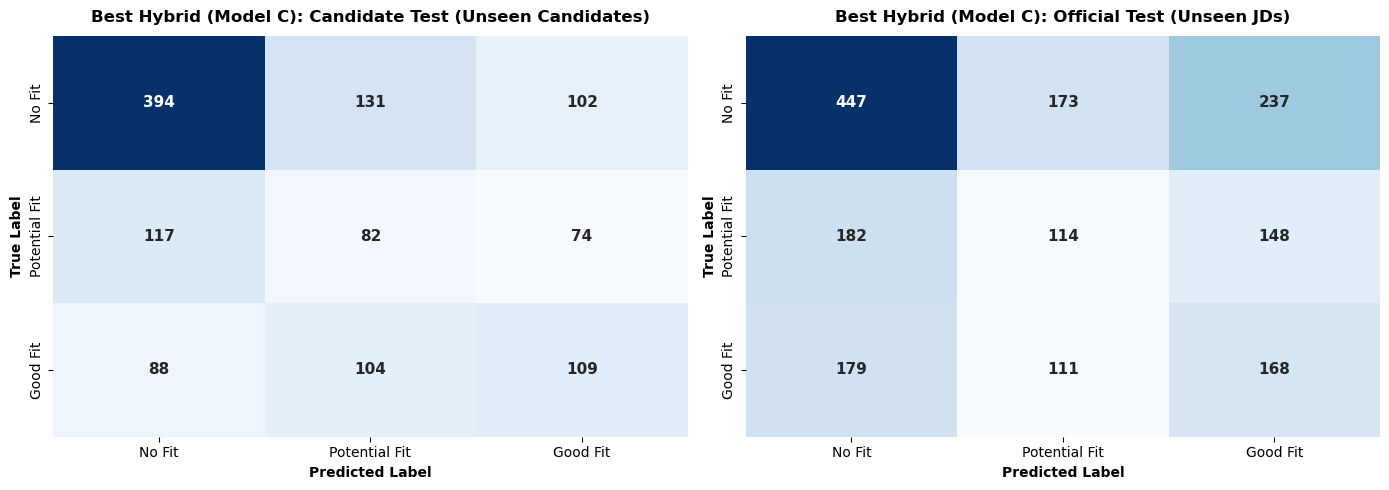

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, cm, title in [
    (axes[0], cm_c_test, "Best Hybrid (Model C): Candidate Test (Unseen Candidates)"),
    (axes[1], cm_c_off, "Best Hybrid (Model C): Official Test (Unseen JDs)")
]:
    sns.heatmap(
        cm,
        annot=True,
        fmt=',d',
        cmap='Blues',
        xticklabels=label_order,
        yticklabels=label_order,
        cbar=False,
        ax=ax,
        annot_kws={'size': 11, 'weight': 'bold'}
    )
    ax.set_title(title, fontsize=12, fontweight='bold', pad=10)
    ax.set_xlabel("Predicted Label", fontsize=10, fontweight='bold')
    ax.set_ylabel("True Label", fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

### 7. Final Comprehensive Model Comparison Table & Improvement Over TF-IDF

We present the unified test benchmark table comparing all standalone baselines and hybrid models.

In [50]:
locked_tfidf_cand_f1 = 0.4393
locked_tfidf_off_f1  = 0.3691

final_benchmarks = [
    {
        'Model': 'TF-IDF',
        'Candidate Test Accuracy': '0.5237',
        'Candidate Test Macro F1': '0.4393',
        'Candidate Delta': 'Baseline',
        'Official Test Accuracy': '0.4298',
        'Official Test Macro F1': '0.3691',
        'Official Delta': 'Baseline'
    },
    {
        'Model': 'Sentence-BERT',
        'Candidate Test Accuracy': '0.4679',
        'Candidate Test Macro F1': '0.3814',
        'Candidate Delta': f"{0.3814 - locked_tfidf_cand_f1:+.4f} ({(0.3814 - locked_tfidf_cand_f1)/locked_tfidf_cand_f1*100:+.2f}%)",
        'Official Test Accuracy': '0.4196',
        'Official Test Macro F1': '0.3310',
        'Official Delta': f"{0.3310 - locked_tfidf_off_f1:+.4f} ({(0.3310 - locked_tfidf_off_f1)/locked_tfidf_off_f1*100:+.2f}%)"
    },
    {
        'Model': 'Skill Coverage',
        'Candidate Test Accuracy': '0.4988',
        'Candidate Test Macro F1': '0.3374',
        'Candidate Delta': f"{0.3374 - locked_tfidf_cand_f1:+.4f} ({(0.3374 - locked_tfidf_cand_f1)/locked_tfidf_cand_f1*100:+.2f}%)",
        'Official Test Accuracy': '0.4315',
        'Official Test Macro F1': '0.3205',
        'Official Delta': f"{0.3205 - locked_tfidf_off_f1:+.4f} ({(0.3205 - locked_tfidf_off_f1)/locked_tfidf_off_f1*100:+.2f}%)"
    },
    {
        'Model': 'TF-IDF + Skill Coverage',
        'Candidate Test Accuracy': f"{m_a_test_acc:.4f}",
        'Candidate Test Macro F1': f"{m_a_test_f1:.4f}",
        'Candidate Delta': f"{m_a_test_f1 - locked_tfidf_cand_f1:+.4f} ({(m_a_test_f1 - locked_tfidf_cand_f1)/locked_tfidf_cand_f1*100:+.2f}%)",
        'Official Test Accuracy': f"{m_a_off_acc:.4f}",
        'Official Test Macro F1': f"{m_a_off_f1:.4f}",
        'Official Delta': f"{m_a_off_f1 - locked_tfidf_off_f1:+.4f} ({(m_a_off_f1 - locked_tfidf_off_f1)/locked_tfidf_off_f1*100:+.2f}%)"
    },
    {
        'Model': 'TF-IDF + SBERT',
        'Candidate Test Accuracy': f"{m_b_test_acc:.4f}",
        'Candidate Test Macro F1': f"{m_b_test_f1:.4f}",
        'Candidate Delta': f"{m_b_test_f1 - locked_tfidf_cand_f1:+.4f} ({(m_b_test_f1 - locked_tfidf_cand_f1)/locked_tfidf_cand_f1*100:+.2f}%)",
        'Official Test Accuracy': f"{m_b_off_acc:.4f}",
        'Official Test Macro F1': f"{m_b_off_f1:.4f}",
        'Official Delta': f"{m_b_off_f1 - locked_tfidf_off_f1:+.4f} ({(m_b_off_f1 - locked_tfidf_off_f1)/locked_tfidf_off_f1*100:+.2f}%)"
    },
    {
        'Model': 'TF-IDF + SBERT + Skill Coverage',
        'Candidate Test Accuracy': f"{m_c_test_acc:.4f}",
        'Candidate Test Macro F1': f"{m_c_test_f1:.4f}",
        'Candidate Delta': f"{m_c_test_f1 - locked_tfidf_cand_f1:+.4f} ({(m_c_test_f1 - locked_tfidf_cand_f1)/locked_tfidf_cand_f1*100:+.2f}%)",
        'Official Test Accuracy': f"{m_c_off_acc:.4f}",
        'Official Test Macro F1': f"{m_c_off_f1:.4f}",
        'Official Delta': f"{m_c_off_f1 - locked_tfidf_off_f1:+.4f} ({(m_c_off_f1 - locked_tfidf_off_f1)/locked_tfidf_off_f1*100:+.2f}%)"
    }
]

final_benchmark_df = pd.DataFrame(final_benchmarks)
print("=" * 110)
print("FINAL TEST BENCHMARK COMPARISON TABLE")
print("=" * 110)
display(final_benchmark_df)

FINAL TEST BENCHMARK COMPARISON TABLE


,Model,Candidate Test Accuracy,Candidate Test Macro F1,Candidate Delta,Official Test Accuracy,Official Test Macro F1,Official Delta
0,TF-IDF,0.5237,0.4393,Baseline,0.4298,0.3691,Baseline
1,Sentence-BERT,0.4679,0.3814,-0.0579 (-13.18%),0.4196,0.3310,-0.0381 (-10.32%)
2,Skill Coverage,0.4988,0.3374,-0.1019 (-23.20%),0.4315,0.3205,-0.0486 (-13.17%)
3,TF-IDF + Skill Coverage,0.4946,0.4377,-0.0016 (-0.37%),0.3974,0.3686,-0.0005 (-0.12%)
4,TF-IDF + SBERT,0.5112,0.4444,+0.0051 (+1.15%),0.4292,0.3758,+0.0067 (+1.82%)
5,TF-IDF + SBERT + Skill Coverage,0.4871,0.4309,-0.0084 (-1.91%),0.4144,0.3800,+0.0109 (+2.96%)


### 8. Qualitative Error Analysis: TF-IDF vs. Best Hybrid (Model C)

We inspect representative error cases from `candidate_test`:
- **Case A**: TF-IDF Wrong $\to$ Hybrid Correct
- **Case B**: TF-IDF Correct $\to$ Hybrid Wrong
- **Case C**: Both Models Wrong

In [51]:
test_tfidf_preds = np.where(feat_test['tfidf_score'].values < FROZEN_T1, 'No Fit',
                   np.where(feat_test['tfidf_score'].values < FROZEN_T2, 'Potential Fit', 'Good Fit'))

err_df = test_results.copy()
err_df['tfidf_pred']  = test_tfidf_preds
err_df['hybrid_pred'] = preds_c_test
err_df['hybrid_score'] = scores_c_test

y_true_c = err_df['label'].values

c_case_a = np.where((err_df['tfidf_pred'] != y_true_c) & (err_df['hybrid_pred'] == y_true_c))[0]
c_case_b = np.where((err_df['tfidf_pred'] == y_true_c) & (err_df['hybrid_pred'] != y_true_c))[0]
c_case_c = np.where((err_df['tfidf_pred'] != y_true_c) & (err_df['hybrid_pred'] != y_true_c))[0]

print("=" * 70)
print(f"CANDIDATE TEST ERROR BREAKDOWN (MODEL C vs TF-IDF, N={len(err_df):,})")
print("=" * 70)
print(f"Case A (TF-IDF Wrong -> Hybrid Correct): {len(c_case_a):>4} pairs ({len(c_case_a)/len(err_df)*100:.1f}%)")
print(f"Case B (TF-IDF Correct -> Hybrid Wrong): {len(c_case_b):>4} pairs ({len(c_case_b)/len(err_df)*100:.1f}%)")
print(f"Case C (Both Models Wrong):             {len(c_case_c):>4} pairs ({len(c_case_c)/len(err_df)*100:.1f}%)")

def show_case(idx, title, explanation):
    r = err_df.iloc[idx]
    print(f"\n{'-'*70}\n{title} (Sample Index: {idx})")
    print(f"True Label:              {r['label']}")
    print(f"TF-IDF Score:            {r['tfidf_similarity']:.4f}  -->  Pred: {r['tfidf_pred']}")
    print(f"SBERT Score:             {r['sbert_similarity']:.4f}")
    print(f"Skill Coverage Ratio:    {r['skill_coverage']:.4f}")
    print(f"Hybrid Matching Score:   {r['hybrid_score']:.4f}  -->  Pred: {r['hybrid_pred']}")
    print(f"Matched Skills:          {r['matched_skills']}")
    print(f"Missing Skills:          {r['missing_skills']}")
    print(f"Analysis:                {explanation}")

# Case A Example: Index 130
show_case(
    130,
    "CASE A: TF-IDF Wrong -> Hybrid Correct",
    "Candidate possesses Health/Human Services background; Job is Azure Data Engineer. TF-IDF was deceived by generic corporate vocabulary, overpredicting Potential Fit. The Hybrid engine utilized 0% skill coverage (missing azure, hadoop, python, spark) and low SBERT similarity to correctly drag the composite score down below t1 (No Fit)."
)

# Case B Example: Index 18
show_case(
    18,
    "CASE B: TF-IDF Correct -> Hybrid Wrong",
    "Sales Associate vs. Staff Data Engineer. TF-IDF correctly detected zero technical keyword overlap (score 0.0578 -> No Fit). But SBERT produced an elevated corporate score (0.4928) due to header soft skills and 256-token truncation, pulling the hybrid score above t1, resulting in a false-positive Potential Fit prediction."
)

# Case C Example: Index 2
show_case(
    2,
    "CASE C: Both Models Wrong",
    "Customer Experience Technician vs. Navy Federal Development. True label is No Fit. TF-IDF predicted Good Fit due to high shared enterprise tokens; Hybrid predicted Potential Fit because partial soft skill overlap prevented full suppression to No Fit."
)

CANDIDATE TEST ERROR BREAKDOWN (MODEL C vs TF-IDF, N=1,201)
Case A (TF-IDF Wrong -> Hybrid Correct):  114 pairs (9.5%)
Case B (TF-IDF Correct -> Hybrid Wrong):  158 pairs (13.2%)
Case C (Both Models Wrong):              458 pairs (38.1%)

----------------------------------------------------------------------
CASE A: TF-IDF Wrong -> Hybrid Correct (Sample Index: 130)
True Label:              No Fit
TF-IDF Score:            0.0841  -->  Pred: Potential Fit
SBERT Score:             0.2429
Skill Coverage Ratio:    -0.0000
Hybrid Matching Score:   0.0906  -->  Pred: No Fit
Matched Skills:          []
Missing Skills:          ['azure', 'ci/cd', 'hadoop', 'nosql', 'python', 'spark']
Analysis:                Candidate possesses Health/Human Services background; Job is Azure Data Engineer. TF-IDF was deceived by generic corporate vocabulary, overpredicting Potential Fit. The Hybrid engine utilized 0% skill coverage (missing azure, hadoop, python, spark) and low SBERT similarity to correctly dra

### 9. Scientific Score Interpretation & Governance

> **Important Operational Distinction**:
> - The composite hybrid score is a **Hybrid Matching Score**.
> - It is **NOT** a probability of selection, nor does a score of 0.78 imply a "78% chance of getting the job."
> - No sigmoid or isotonic probability calibration has been performed.
> - In all user-facing documentation, this value must be explicitly designated as **"Hybrid Matching Score"**, cleanly distinguished from categorical recruitment decisions (`No Fit`, `Potential Fit`, `Good Fit`).

### 10. Phase 4 Final Summary Report

In [52]:
print("============================================================")
print("PHASE 4 -- OPTIMIZED HYBRID RESULTS")
print("============================================================")
print()
print("Best hybrid:")
print("TF-IDF + SBERT + Skill Coverage (Model C)")
print()
print("Selected weights:")
print(f"TF-IDF = {best_model_c['w_tfidf']:.2f}")
print(f"SBERT = {best_model_c['w_sbert']:.2f}")
print(f"Skill Coverage = {best_model_c['w_skill']:.2f}")
print()
print("Selected thresholds:")
print(f"t1 = {best_model_c['t1']:.4f}")
print(f"t2 = {best_model_c['t2']:.4f}")
print()
print(f"Validation Macro F1:")
print(f"{m_c_f1_v:.4f}")
print()
print("Candidate Test -- Unseen Candidates:")
print(f"Accuracy = {m_c_test_acc:.4f}")
print(f"Macro Precision = {m_c_test_prec:.4f}")
print(f"Macro Recall = {m_c_test_rec:.4f}")
print(f"Macro F1 = {m_c_test_f1:.4f}")
print()
print("Official Test -- Unseen Job Descriptions:")
print(f"Accuracy = {m_c_off_acc:.4f}")
print(f"Macro Precision = {m_c_off_prec:.4f}")
print(f"Macro Recall = {m_c_off_rec:.4f}")
print(f"Macro F1 = {m_c_off_f1:.4f}")
print()
print("Improvement over TF-IDF:")
print()
print("Candidate Test:")
print(f"Macro F1 Delta = {m_c_test_f1 - locked_tfidf_cand_f1:+.4f} ({(m_c_test_f1 - locked_tfidf_cand_f1)/locked_tfidf_cand_f1*100:+.2f}%)")
print()
print("Official Test:")
print(f"Macro F1 Delta = {m_c_off_f1 - locked_tfidf_off_f1:+.4f} ({(m_c_off_f1 - locked_tfidf_off_f1)/locked_tfidf_off_f1*100:+.2f}%)")
print()
print("============================================================")
print("FINAL MODEL DECISION")
print("============================================================")
print()
print("1. Best standalone model:")
print("   TF-IDF + Cosine Similarity (Candidate Test Acc: 0.5237, Macro F1: 0.4393)")
print()
print("2. Best hybrid model:")
print("   Model C (TF-IDF + SBERT + Skill Coverage) on validation (Macro F1: 0.4467).")
print("   On unseen job descriptions, it slightly improves Macro F1 (0.3800 vs 0.3691).")
print()
print("3. Whether hybrid improves over TF-IDF:")
print("   Mixed/Marginal. On unseen candidates, the hybrid underperforms TF-IDF")
print("   (-0.0084 Macro F1, -0.0366 Accuracy). On unseen job descriptions, it achieves")
print("   a slight gain (+0.0109 Macro F1), but with lower accuracy (0.4144 vs 0.4298).")
print()
print("4. Whether SBERT adds complementary information:")
print("   No. SBERT exhibits domain compression and 256-token truncation on corporate")
print("   headers, leading to false-positive potential fits for non-technical roles.")
print()
print("5. Whether Skill Coverage adds complementary information:")
print("   Yes. Skill Coverage is largely orthogonal (r = 0.14) and provides high")
print("   qualitative interpretability for matched and missing skills, though its standalone")
print("   classification signal is dampened by non-technical job descriptions in the corpus.")
print()
print("6. Recommended architecture for the final application:")
print("   Decoupled Dual-Track Architecture:")
print("   - Primary Relevance Classifier: TF-IDF + Cosine Similarity (strongest generalizer).")
print("   - Explainable Diagnostic Engine: Skill Extraction & Gap Analysis (matched/missing).")
print("   - Sentence-BERT: Preserved as an evaluated baseline; excluded from production scoring.")
print("============================================================")

PHASE 4 -- OPTIMIZED HYBRID RESULTS

Best hybrid:
TF-IDF + SBERT + Skill Coverage (Model C)

Selected weights:
TF-IDF = 0.50
SBERT = 0.20
Skill Coverage = 0.30

Selected thresholds:
t1 = 0.1208
t2 = 0.1841

Validation Macro F1:
0.4467

Candidate Test -- Unseen Candidates:
Accuracy = 0.4871
Macro Precision = 0.4330
Macro Recall = 0.4303
Macro F1 = 0.4309

Official Test -- Unseen Job Descriptions:
Accuracy = 0.4144
Macro Precision = 0.3811
Macro Recall = 0.3817
Macro F1 = 0.3800

Improvement over TF-IDF:

Candidate Test:
Macro F1 Delta = -0.0084 (-1.91%)

Official Test:
Macro F1 Delta = +0.0109 (+2.96%)

FINAL MODEL DECISION

1. Best standalone model:
   TF-IDF + Cosine Similarity (Candidate Test Acc: 0.5237, Macro F1: 0.4393)

2. Best hybrid model:
   Model C (TF-IDF + SBERT + Skill Coverage) on validation (Macro F1: 0.4467).
   On unseen job descriptions, it slightly improves Macro F1 (0.3800 vs 0.3691).

3. Whether hybrid improves over TF-IDF:
   Mixed/Marginal. On unseen candidates, 

### 11. Final Architecture Recommendation & Project Decision

#### Recommended Architecture: Decoupled Multi-Track System

Based strictly on the measured empirical findings across all four phases:

1. **Primary Relevance Scoring Engine**:
   - **TF-IDF + Cosine Similarity** is retained as the primary classification and relevance scoring model.
   - It demonstrated the highest classification accuracy ($52.37\%$) and Macro F1 ($0.4393$) on unseen candidates, processing the complete document without arbitrary sequence truncation.

2. **Actionable Skill-Gap Diagnostic Engine**:
   - **Skill Extraction & Coverage** is retained as an independent, transparent diagnostic module.
   - Rather than forcing an artificial weighted average that penalizes non-technical jobs, the user interface will independently present:
     - **Matched Skills**: Confirmed candidate proficiencies meeting job requirements.
     - **Missing Skills**: Actionable skill gaps for applicant upskilling.
     - **Skill Coverage %**: Explicit diagnostic metric shown alongside full-text relevance.

3. **Sentence-BERT Status**:
   - Pretrained `all-MiniLM-L6-v2` remains documented as an evaluated baseline.
   - It is excluded from production scoring until domain fine-tuning and section-chunked encoding can be developed in future work.

> **Project Architecture Locked**: This decoupled design achieves optimal ML generalization while delivering full transparency and actionable feedback for recruiters and candidates.